# Entrega 2

**Proyecto:** predicción de resultados de fútbol europeo (victoria local / empate / victoria visitante) — Andes Sports Analytics.
**Fuente:** *European Soccer Database* (SQLite), 7 tablas: `Player`, `Player_Attributes`, `Team`, `Team_Attributes`, `League`, `Country`, `Match`.

Se trabaja **una tabla a la vez**: cada una queda en su propio DataFrame para en una primera parte hacer el análisis y comprensión de los datos.

## Configuración inicial

In [ ]:
from sqlalchemy import create_engine
from pathlib import Path
import pandas as pd
import numpy as np

file_path = Path("/content/database.sqlite")
engine = create_engine(f'sqlite:///{file_path}')

tablas = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table';", engine)
tablas

,name
0,sqlite_sequence
1,Player_Attributes
2,Player
3,Match
4,League
5,Country
6,Team
7,Team_Attributes


Antes de recorrer todas las tablas, definimos una función auxiliar que resume dimensiones, tipos, duplicados y nulos, para no repetir el mismo bloque de código siete veces. La función solo *reporta*; las decisiones de qué descartar y cómo limpiar se toman manualmente tabla por tabla.

In [ ]:
def resumen_general(df, nombre):
    print(f"===== {nombre} =====")
    print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
    print()
    print("Tipos de dato:")
    print(df.dtypes.value_counts())
    print()
    dup_filas = df.duplicated().sum()
    print(f"Filas completamente duplicadas: {dup_filas}")
    print()
    nulos = df.isnull().sum()
    nulos = nulos[nulos > 0].sort_values(ascending=False)
    if nulos.empty:
        print("Sin valores nulos.")
    else:
        tabla_nulos = pd.DataFrame({
            'nulos': nulos,
            'porcentaje': (nulos / len(df) * 100).round(2)
        })
        print("Columnas con valores nulos:")
        print(tabla_nulos)
    return dup_filas, nulos

## 1. Carga y comprensión de los datos

### 1.1 Tabla `Player`

In [ ]:
# 1.a Carga
df_player = pd.read_sql("SELECT * FROM Player", engine)
df_player.head()

,id,player_api_id,player_name,player_fifa_api_id,birthday,height,weight
0,1,505942,Aaron Appindangoye,218353,1992-02-29 00:00:00,182.88,187
1,2,155782,Aaron Cresswell,189615,1989-12-15 00:00:00,170.18,146
2,3,162549,Aaron Doran,186170,1991-05-13 00:00:00,170.18,163
3,4,30572,Aaron Galindo,140161,1982-05-08 00:00:00,182.88,198
4,5,23780,Aaron Hughes,17725,1979-11-08 00:00:00,182.88,154


In [ ]:
# 1.b Dimensiones y tipos de dato
resumen_general(df_player, "Player")
df_player.dtypes

===== Player =====
Filas: 11,060 | Columnas: 7

Tipos de dato:
int64      4
object     2
float64    1
Name: count, dtype: int64

Filas completamente duplicadas: 0

Sin valores nulos.


,0
id,int64
player_api_id,int64
player_name,object
player_fifa_api_id,int64
birthday,object
height,float64
weight,int64


In [ ]:
# 1.b Continuamos haciendo corrección de tipos: 'birthday' llega como texto, debe ser fecha
df_player['birthday'] = pd.to_datetime(df_player['birthday'])
df_player.dtypes

,0
id,int64
player_api_id,int64
player_name,object
player_fifa_api_id,int64
birthday,datetime64[ns]
height,float64
weight,int64


In [ ]:
# 1.c Estadísticas descriptivas (numéricas y categóricas)
print("Numéricas:")
display(df_player.describe())
print()
print("Categóricas:")
display(df_player.describe(include='object'))

Numéricas:


,id,player_api_id,player_fifa_api_id,birthday,height,weight
count,11060.000000,11060.000000,11060.000000,11060,11060.000000,11060.000000
mean,5537.511392,156582.427215,165664.910488,1987-02-03 21:19:20.072332800,181.867445,168.380289
min,1.000000,2625.000000,2.000000,1967-01-23 00:00:00,157.480000,117.000000
25%,2767.750000,35555.500000,151889.500000,1983-03-17 00:00:00,177.800000,159.000000
50%,5536.500000,96619.500000,184671.000000,1987-07-08 00:00:00,182.880000,168.000000
75%,8306.250000,212470.500000,203883.250000,1991-04-12 00:00:00,185.420000,179.000000
max,11075.000000,750584.000000,234141.000000,1999-04-24 00:00:00,208.280000,243.000000
std,3197.692647,160713.700624,58649.928360,NaN,6.369201,14.990217



Categóricas:


,player_name
count,11060
unique,10848
top,Danilo
freq,7


In [ ]:
# 1.d Duplicados: fila completa y por clave vamos a usar player_api_id
dup_full = df_player.duplicated().sum()
dup_key = df_player.duplicated(subset=['player_api_id']).sum()
dup_name = df_player.duplicated(subset=['player_name'], keep=False).sum()
print("Duplicados de fila completa:", dup_full)
print("Duplicados por player_api_id:", dup_key)
print("Filas que comparten player_name con al menos otro jugador:", dup_name)
df_player[df_player.duplicated(subset=['player_name'], keep=False)].sort_values('player_name').head(6)

Duplicados de fila completa: 0
Duplicados por player_api_id: 0
Filas que comparten player_name con al menos otro jugador: 375


,id,player_api_id,player_name,player_fifa_api_id,birthday,height,weight
84,85,26331,Adailton,158505,1983-04-14,190.50,187
85,86,41749,Adailton,4769,1977-01-24,175.26,161
98,99,23133,Adam Drury,101882,1978-08-29,180.34,161
99,100,420209,Adam Drury,205162,1993-09-09,177.80,152
137,138,181211,Adama Traore,193177,1990-02-03,170.18,161
138,139,533212,Adama Traore,225151,1995-06-28,177.80,159


In [ ]:
# 1.e Nulos
df_player.isnull().sum()

,0
id,0
player_api_id,0
player_name,0
player_fifa_api_id,0
birthday,0
height,0
weight,0


**1.f — Hallazgos (`Player`).** 11.060 registros, 7 variables, sin nulos y sin filas duplicadas ni por fila completa ni por `player_api_id` (la clave es única). Hay 375 filas cuyo `player_name` coincide con el de otro jugador (ej. dos jugadores distintos llamados "Adailton", con `player_api_id` y `birthday` diferentes): son homónimos, no duplicados reales, así que no se eliminan. `birthday` llegaba como texto y se convirtió a fecha. `height`/`weight` son numéricas continuas sin valores atípicos evidentes en el `describe()`.

### 1.2 Tabla `Player_Attributes`

In [ ]:
# 1.a Carga
df_player_attr = pd.read_sql("SELECT * FROM Player_Attributes", engine)
df_player_attr.head()

,id,player_fifa_api_id,player_api_id,date,overall_rating,potential,preferred_foot,attacking_work_rate,defensive_work_rate,crossing,...,vision,penalties,marking,standing_tackle,sliding_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes
0,1,218353,505942,2016-02-18 00:00:00,67.0,71.0,right,medium,medium,49.0,...,54.0,48.0,65.0,69.0,69.0,6.0,11.0,10.0,8.0,8.0
1,2,218353,505942,2015-11-19 00:00:00,67.0,71.0,right,medium,medium,49.0,...,54.0,48.0,65.0,69.0,69.0,6.0,11.0,10.0,8.0,8.0
2,3,218353,505942,2015-09-21 00:00:00,62.0,66.0,right,medium,medium,49.0,...,54.0,48.0,65.0,66.0,69.0,6.0,11.0,10.0,8.0,8.0
3,4,218353,505942,2015-03-20 00:00:00,61.0,65.0,right,medium,medium,48.0,...,53.0,47.0,62.0,63.0,66.0,5.0,10.0,9.0,7.0,7.0
4,5,218353,505942,2007-02-22 00:00:00,61.0,65.0,right,medium,medium,48.0,...,53.0,47.0,62.0,63.0,66.0,5.0,10.0,9.0,7.0,7.0


In [ ]:
# 1.b Dimensiones y tipos de dato
resumen_general(df_player_attr, "Player_Attributes")

===== Player_Attributes =====
Filas: 183,978 | Columnas: 42

Tipos de dato:
float64    35
object      4
int64       3
Name: count, dtype: int64

Filas completamente duplicadas: 0

Columnas con valores nulos:
                     nulos  porcentaje
attacking_work_rate   3230        1.76
jumping               2713        1.47
agility               2713        1.47
balance               2713        1.47
curve                 2713        1.47
volleys               2713        1.47
sliding_tackle        2713        1.47
vision                2713        1.47
crossing               836        0.45
potential              836        0.45
overall_rating         836        0.45
defensive_work_rate    836        0.45
preferred_foot         836        0.45
short_passing          836        0.45
long_passing           836        0.45
free_kick_accuracy     836        0.45
dribbling              836        0.45
ball_control           836        0.45
sprint_speed           836        0.45
acceleration

(np.int64(0),
 attacking_work_rate    3230
 jumping                2713
 agility                2713
 balance                2713
 curve                  2713
 volleys                2713
 sliding_tackle         2713
 vision                 2713
 crossing                836
 potential               836
 overall_rating          836
 defensive_work_rate     836
 preferred_foot          836
 short_passing           836
 long_passing            836
 free_kick_accuracy      836
 dribbling               836
 ball_control            836
 sprint_speed            836
 acceleration            836
 heading_accuracy        836
 finishing               836
 shot_power              836
 reactions               836
 long_shots              836
 stamina                 836
 aggression              836
 interceptions           836
 positioning             836
 strength                836
 penalties               836
 marking                 836
 standing_tackle         836
 gk_diving               836


In [ ]:
# 1.b Continuamos haciendo corrección de tipos: 'date' llega como texto, debe ser fecha
df_player_attr['date'] = pd.to_datetime(df_player_attr['date'])
df_player_attr.dtypes

,0
id,int64
player_fifa_api_id,int64
player_api_id,int64
date,datetime64[ns]
overall_rating,float64
potential,float64
preferred_foot,object
attacking_work_rate,object
defensive_work_rate,object
crossing,float64


In [ ]:
# 1.c Estadísticas descriptivas
print("Numéricas:")
display(df_player_attr.describe())
print()
print("Categóricas:")
display(df_player_attr.describe(include="object"))

Numéricas:


,id,player_fifa_api_id,player_api_id,date,overall_rating,potential,crossing,finishing,heading_accuracy,short_passing,...,vision,penalties,marking,standing_tackle,sliding_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes
count,183978.00000,183978.000000,183978.000000,183978,183142.000000,183142.000000,183142.000000,183142.000000,183142.000000,183142.000000,...,181265.000000,183142.000000,183142.000000,183142.000000,181265.000000,183142.000000,183142.000000,183142.000000,183142.000000,183142.000000
mean,91989.50000,165671.524291,135900.617324,2012-12-07 05:49:56.771353088,68.600015,73.460353,55.086883,49.921078,57.266023,62.429672,...,57.873550,55.003986,46.772242,50.351257,48.001462,14.704393,16.063612,20.998362,16.132154,16.441439
min,1.00000,2.000000,2625.000000,2007-02-22 00:00:00,33.000000,39.000000,1.000000,1.000000,1.000000,3.000000,...,1.000000,2.000000,1.000000,1.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,45995.25000,155798.000000,34763.000000,2011-02-22 00:00:00,64.000000,69.000000,45.000000,34.000000,49.000000,57.000000,...,49.000000,45.000000,25.000000,29.000000,25.000000,7.000000,8.000000,8.000000,8.000000,8.000000
50%,91989.50000,183488.000000,77741.000000,2013-09-20 00:00:00,69.000000,74.000000,59.000000,53.000000,60.000000,65.000000,...,60.000000,57.000000,50.000000,56.000000,53.000000,10.000000,11.000000,12.000000,11.000000,11.000000
75%,137983.75000,199848.000000,191080.000000,2014-12-19 00:00:00,73.000000,78.000000,68.000000,65.000000,68.000000,72.000000,...,69.000000,67.000000,66.000000,69.000000,67.000000,13.000000,15.000000,15.000000,15.000000,15.000000
max,183978.00000,234141.000000,750584.000000,2016-07-07 00:00:00,94.000000,97.000000,95.000000,97.000000,98.000000,97.000000,...,97.000000,96.000000,96.000000,95.000000,95.000000,94.000000,93.000000,97.000000,96.000000,96.000000
std,53110.01825,53851.094769,136927.840510,NaN,7.041139,6.592271,17.242135,19.038705,16.488905,14.194068,...,15.144086,15.546519,21.227667,21.483706,21.598778,16.865467,15.867382,21.452980,16.099175,17.198155



Categóricas:


,preferred_foot,attacking_work_rate,defensive_work_rate
count,183142,180748,183142
unique,2,8,19
top,right,medium,medium
freq,138409,125070,130846


In [ ]:
# 1.d Duplicados: fila completa y por clave (player_api_id, date)
dup_full = df_player_attr.duplicated().sum()
dup_key = df_player_attr.duplicated(subset=['player_api_id', 'date']).sum()
print("Duplicados de fila completa:", dup_full)
print("Duplicados por (player_api_id, date):", dup_key)

# miramos, qué contienen las filas que comparten clave?
ejemplo = df_player_attr[df_player_attr.duplicated(subset=['player_api_id', 'date'], keep=False)]
ejemplo.sort_values(['player_api_id', 'date'])[['id', 'player_api_id', 'date', 'overall_rating', 'potential']].head(6)

Duplicados de fila completa: 0
Duplicados por (player_api_id, date): 836


,id,player_api_id,date,overall_rating,potential
66778,66779,2907,2007-02-22,54.0,60.0
66779,66780,2907,2007-02-22,NaN,NaN
8063,8064,3517,2007-02-22,81.0,90.0
8064,8065,3517,2007-02-22,NaN,NaN
91977,91978,5243,2007-02-22,71.0,70.0
91978,91979,5243,2007-02-22,NaN,NaN


In [ ]:
# 1.e Nulos
nulos = df_player_attr.isnull().sum()
nulos[nulos > 0].sort_values(ascending=False)

,0
attacking_work_rate,3230
jumping,2713
agility,2713
balance,2713
curve,2713
volleys,2713
sliding_tackle,2713
vision,2713
crossing,836
potential,836


In [ ]:
# 1.e Continuamos miranfo valores categóricos "sucios" en las work rate
print("attacking_work_rate:")
print(df_player_attr['attacking_work_rate'].value_counts(dropna=False))
print()
print("defensive_work_rate:")
print(df_player_attr['defensive_work_rate'].value_counts(dropna=False))

attacking_work_rate:
attacking_work_rate
medium    125070
high       42823
low         8569
None        3639
None        3230
norm         348
y            106
le           104
stoc          89
Name: count, dtype: int64

defensive_work_rate:
defensive_work_rate
medium    130846
high       27041
low        18432
_0          2394
o           1550
None         836
1            441
ormal        348
2            342
3            258
5            234
7            217
6            197
0            197
9            152
4            116
es           106
ean          104
tocky         89
8             78
Name: count, dtype: int64


In [ ]:
# Filas totales involucradas en pares duplicados
print("Filas totales involucradas en pares duplicados:", len(ejemplo))

# ¿en cada par, una fila tiene TODOS los atributos nulos?
cols_atributo = [c for c in df_player_attr.columns if c not in
                 ['id', 'player_fifa_api_id', 'player_api_id', 'date']]
filas_totalmente_nulas = ejemplo[cols_atributo].isnull().all(axis=1)
print("De esas filas, cuántas tienen los", len(cols_atributo), "atributos completamente nulos:",
      filas_totalmente_nulas.sum())

Filas totales involucradas en pares duplicados: 1671
De esas filas, cuántas tienen los 38 atributos completamente nulos: 836


**1.f — Hallazgos (`Player_Attributes`).** 183.978 registros, 42 variables. Hay 836 pares duplicados de la clave natural `(player_api_id, date)`, que en total involucran 1.671 filas; al inspeccionarlos, en cada par una fila tiene los atributos completos y la otra los tiene **todos nulos** (mismo `player_fifa_api_id`, mismo `player_api_id`, misma fecha). Esto explica por qué prácticamente todas las columnas de atributos numéricos tienen exactamente 836 nulos (0,5%): no es que falten valores, es que existen "filas fantasma", estas las vamos a eliminar

Además, `attacking_work_rate` y `defensive_work_rate` tienen valores que no corresponden a las tres categorías esperadas (`low`/`medium`/`high`): aparecen fragmentos de texto y dígitos sueltos (`'norm'`, `'stoc'`, `'le'`, `'y'` en la primera; `'_0'`, `'o'`, `'1'`, `'ormal'`, dígitos del 0 al 9, `'es'`, `'ean'`, `'tocky'` en la segunda), que suman cerca de 4% de los registros en cada variable. Es un problema de calidad de la fuente (aparentan ser fragmentos truncados de "normal"/"stocky"), no un faltante aleatorio, y se tratarán como categoría inválida en vez de imputarlos a una de las tres clases válidas.

### 1.3 Tabla `Team`

In [ ]:
# 1.a Carga
df_team = pd.read_sql("SELECT * FROM Team", engine)
df_team.head()

,id,team_api_id,team_fifa_api_id,team_long_name,team_short_name
0,1,9987,673.0,KRC Genk,GEN
1,2,9993,675.0,Beerschot AC,BAC
2,3,10000,15005.0,SV Zulte-Waregem,ZUL
3,4,9994,2007.0,Sporting Lokeren,LOK
4,5,9984,1750.0,KSV Cercle Brugge,CEB


In [ ]:
# 1.b Dimensiones y tipos
resumen_general(df_team, "Team")

===== Team =====
Filas: 299 | Columnas: 5

Tipos de dato:
int64      2
object     2
float64    1
Name: count, dtype: int64

Filas completamente duplicadas: 0

Columnas con valores nulos:
                  nulos  porcentaje
team_fifa_api_id     11        3.68


(np.int64(0),
 team_fifa_api_id    11
 dtype: int64)

In [ ]:
# 1.c Estadísticas descriptivas
print("Numéricas:")
display(df_team.describe())
print()
print("Categóricas:")
display(df_team.describe(include='object'))

Numéricas:


,id,team_api_id,team_fifa_api_id
count,299.000000,299.000000,288.000000
mean,23735.301003,12340.521739,21534.305556
std,15167.914719,25940.411135,42456.439408
min,1.000000,1601.000000,1.000000
25%,9552.500000,8349.000000,178.750000
50%,22805.000000,8655.000000,673.500000
75%,36250.500000,9886.500000,1910.750000
max,51606.000000,274581.000000,112513.000000



Categóricas:


,team_long_name,team_short_name
count,299,299
unique,296,259
top,Polonia Bytom,POR
freq,2,3


In [ ]:
# 1.d Duplicados
print("Duplicados de fila completa:", df_team.duplicated().sum())
print("Duplicados por team_api_id:", df_team.duplicated(subset=['team_api_id']).sum())

Duplicados de fila completa: 0
Duplicados por team_api_id: 0


In [ ]:
# 1.e Nulos
df_team[df_team['team_fifa_api_id'].isnull()][['team_api_id', 'team_long_name', 'team_short_name']]

,team_api_id,team_long_name,team_short_name
8,7947,FCV Dender EH,DEN
14,4049,Tubize,TUB
170,6601,FC Volendam,VOL
204,177361,Termalica Bruk-Bet Nieciecza,TBN
208,7992,Trofense,TRO
213,10213,Amadora,AMA
223,9765,Portimonense,POR
225,4064,Feirense,FEI
232,6367,Uniao da Madeira,MAD
233,188163,Tondela,TON


**1.f — Hallazgos (`Team`).** 299 equipos, 5 variables, sin duplicados. Solo `team_fifa_api_id` tiene nulos (11 equipos, 3,7%); son clubes pequeños o de ligas menores (FCV Dender EH, Tubize, Lugano, etc) que probablemente no estaban en el videojuego FIFA de donde proviene ese identificador, no afecta el uso de `team_api_id` como llave.

### 1.4 Tabla `Team_Attributes`

In [ ]:
# 1.a Carga
df_team_attr = pd.read_sql("SELECT * FROM Team_Attributes", engine)
df_team_attr.head()

,id,team_fifa_api_id,team_api_id,date,buildUpPlaySpeed,buildUpPlaySpeedClass,buildUpPlayDribbling,buildUpPlayDribblingClass,buildUpPlayPassing,buildUpPlayPassingClass,...,chanceCreationShooting,chanceCreationShootingClass,chanceCreationPositioningClass,defencePressure,defencePressureClass,defenceAggression,defenceAggressionClass,defenceTeamWidth,defenceTeamWidthClass,defenceDefenderLineClass
0,1,434,9930,2010-02-22 00:00:00,60,Balanced,NaN,Little,50,Mixed,...,55,Normal,Organised,50,Medium,55,Press,45,Normal,Cover
1,2,434,9930,2014-09-19 00:00:00,52,Balanced,48.0,Normal,56,Mixed,...,64,Normal,Organised,47,Medium,44,Press,54,Normal,Cover
2,3,434,9930,2015-09-10 00:00:00,47,Balanced,41.0,Normal,54,Mixed,...,64,Normal,Organised,47,Medium,44,Press,54,Normal,Cover
3,4,77,8485,2010-02-22 00:00:00,70,Fast,NaN,Little,70,Long,...,70,Lots,Organised,60,Medium,70,Double,70,Wide,Cover
4,5,77,8485,2011-02-22 00:00:00,47,Balanced,NaN,Little,52,Mixed,...,52,Normal,Organised,47,Medium,47,Press,52,Normal,Cover


In [ ]:
# 1.b Dimensiones y tipos
resumen_general(df_team_attr, "Team_Attributes")

===== Team_Attributes =====
Filas: 1,458 | Columnas: 25

Tipos de dato:
object     13
int64      11
float64     1
Name: count, dtype: int64

Filas completamente duplicadas: 0

Columnas con valores nulos:
                      nulos  porcentaje
buildUpPlayDribbling    969       66.46


(np.int64(0),
 buildUpPlayDribbling    969
 dtype: int64)

In [ ]:
# 1.b Continuamos haciendo corrección de tipos: 'date' llega como texto
df_team_attr['date'] = pd.to_datetime(df_team_attr['date'])
df_team_attr.dtypes

,0
id,int64
team_fifa_api_id,int64
team_api_id,int64
date,datetime64[ns]
buildUpPlaySpeed,int64
buildUpPlaySpeedClass,object
buildUpPlayDribbling,float64
buildUpPlayDribblingClass,object
buildUpPlayPassing,int64
buildUpPlayPassingClass,object


In [ ]:
# 1.c Estadísticas descriptivas
print("Numéricas:")
display(df_team_attr.describe())
print()
print("Categóricas:")
display(df_team_attr.describe(include="object"))

Numéricas:


,id,team_fifa_api_id,team_api_id,date,buildUpPlaySpeed,buildUpPlayDribbling,buildUpPlayPassing,chanceCreationPassing,chanceCreationCrossing,chanceCreationShooting,defencePressure,defenceAggression,defenceTeamWidth
count,1458.000000,1458.000000,1458.000000,1458,1458.000000,489.000000,1458.000000,1458.000000,1458.000000,1458.000000,1458.000000,1458.000000,1458.000000
mean,729.500000,17706.982167,9995.727023,2012-12-06 22:40:59.259259392,52.462277,48.607362,48.490398,52.165295,53.731824,53.969136,46.017147,49.251029,52.185871
min,1.000000,1.000000,1601.000000,2010-02-22 00:00:00,20.000000,24.000000,20.000000,21.000000,20.000000,22.000000,23.000000,24.000000,29.000000
25%,365.250000,110.000000,8457.750000,2011-02-22 00:00:00,45.000000,42.000000,40.000000,46.000000,47.000000,48.000000,39.000000,44.000000,47.000000
50%,729.500000,485.000000,8674.000000,2013-09-20 00:00:00,52.000000,49.000000,50.000000,52.000000,53.000000,53.000000,45.000000,48.000000,52.000000
75%,1093.750000,1900.000000,9904.000000,2014-09-19 00:00:00,62.000000,55.000000,55.000000,59.000000,62.000000,61.000000,51.000000,55.000000,58.000000
max,1458.000000,112513.000000,274581.000000,2015-09-10 00:00:00,80.000000,77.000000,80.000000,80.000000,80.000000,80.000000,72.000000,72.000000,73.000000
std,421.032659,39179.857739,13264.869900,NaN,11.545869,9.678290,10.896101,10.360793,11.086796,10.327566,10.227225,9.738028,9.574712



Categóricas:


,buildUpPlaySpeedClass,buildUpPlayDribblingClass,buildUpPlayPassingClass,buildUpPlayPositioningClass,chanceCreationPassingClass,chanceCreationCrossingClass,chanceCreationShootingClass,chanceCreationPositioningClass,defencePressureClass,defenceAggressionClass,defenceTeamWidthClass,defenceDefenderLineClass
count,1458,1458,1458,1458,1458,1458,1458,1458,1458,1458,1458,1458
unique,3,3,3,2,3,3,3,2,3,3,3,2
top,Balanced,Little,Mixed,Organised,Normal,Normal,Normal,Organised,Medium,Press,Normal,Cover
freq,1184,1004,1236,1386,1231,1195,1224,1309,1243,1274,1286,1362


In [ ]:
# 1.d Duplicados: fila completa y por clave (team_api_id, date)
dup_full = df_team_attr.duplicated().sum()
dup_key = df_team_attr.duplicated(subset=['team_api_id', 'date']).sum()
print("Duplicados de fila completa:", dup_full)
print("Duplicados por (team_api_id, date):", dup_key)
df_team_attr[df_team_attr.duplicated(subset=['team_api_id', 'date'], keep=False)]

Duplicados de fila completa: 0
Duplicados por (team_api_id, date): 1


,id,team_fifa_api_id,team_api_id,date,buildUpPlaySpeed,buildUpPlaySpeedClass,buildUpPlayDribbling,buildUpPlayDribblingClass,buildUpPlayPassing,buildUpPlayPassingClass,...,chanceCreationShooting,chanceCreationShootingClass,chanceCreationPositioningClass,defencePressure,defencePressureClass,defenceAggression,defenceAggressionClass,defenceTeamWidth,defenceTeamWidthClass,defenceDefenderLineClass
859,860,111560,9996,2015-09-10,50,Balanced,50.0,Normal,50,Mixed,...,50,Normal,Organised,45,Medium,45,Press,50,Normal,Cover
860,861,111560,9996,2015-09-10,50,Balanced,50.0,Normal,50,Mixed,...,50,Normal,Organised,45,Medium,45,Press,50,Normal,Cover


In [ ]:
# 1.e Nulos y su relación con buildUpPlayDribblingClass
print(df_team_attr.isnull().sum())
print()
print("Tamaño de cada clase de buildUpPlayDribblingClass:")
print(df_team_attr['buildUpPlayDribblingClass'].value_counts())
print()
print("% de nulos en buildUpPlayDribbling, según su propia clase:")
print(df_team_attr.groupby('buildUpPlayDribblingClass')['buildUpPlayDribbling'].apply(lambda s: s.isnull().mean().round(3)))

id                                  0
team_fifa_api_id                    0
team_api_id                         0
date                                0
buildUpPlaySpeed                    0
buildUpPlaySpeedClass               0
buildUpPlayDribbling              969
buildUpPlayDribblingClass           0
buildUpPlayPassing                  0
buildUpPlayPassingClass             0
buildUpPlayPositioningClass         0
chanceCreationPassing               0
chanceCreationPassingClass          0
chanceCreationCrossing              0
chanceCreationCrossingClass         0
chanceCreationShooting              0
chanceCreationShootingClass         0
chanceCreationPositioningClass      0
defencePressure                     0
defencePressureClass                0
defenceAggression                   0
defenceAggressionClass              0
defenceTeamWidth                    0
defenceTeamWidthClass               0
defenceDefenderLineClass            0
dtype: int64

Tamaño de cada clase de buildUpPlayD

**1.f — Hallazgos (`Team_Attributes`).** 1.458 registros, 25 variables. Hay **una fila duplicada exacta** (mismo `team_api_id`, `date` y todos los valores) que se elimina directamente. `buildUpPlayDribbling` tiene más del 50% de nulos, coincide casi a la perfección con la clase `buildUpPlayDribblingClass = 'Little'` (96,5% de esas filas no tienen el valor numérico, mientras que en `'Normal'` y `'Lots'` el valor está completo). Aquí podemos ver que ese atributo se incorporó más tarde a la fuente y, cuando falta, se le asignó por defecto la clase `'Little'`. Como la versión categórica está completa y explica el faltante, se prioriza `buildUpPlayDribblingClass` sobre la variable numérica para el modelo.

### 1.5 Tabla `League`

In [ ]:
# 1.a-1.e Carga y revisión
df_league = pd.read_sql("SELECT * FROM League", engine)
resumen_general(df_league, "League")
df_league

===== League =====
Filas: 11 | Columnas: 3

Tipos de dato:
int64     2
object    1
Name: count, dtype: int64

Filas completamente duplicadas: 0

Sin valores nulos.


,id,country_id,name
0,1,1,Belgium Jupiler League
1,1729,1729,England Premier League
2,4769,4769,France Ligue 1
3,7809,7809,Germany 1. Bundesliga
4,10257,10257,Italy Serie A
5,13274,13274,Netherlands Eredivisie
6,15722,15722,Poland Ekstraklasa
7,17642,17642,Portugal Liga ZON Sagres
8,19694,19694,Scotland Premier League
9,21518,21518,Spain LIGA BBVA


**1.f — Hallazgos (`League`).** 11 ligas, 3 variables, sin duplicados ni nulos. Es una tabla catálogo: `id` identifica la liga y coincide numéricamente con `country_id` en esta fuente (una liga por país), `name` es el nombre de la competición. Solo sirve como llave de unión y para dar contexto legible a `league_id` en `Match`; no aporta variables predictivas por sí sola.

### 1.6 Tabla `Country`

In [ ]:
# 1.a-1.e — Carga y revisión
df_country = pd.read_sql("SELECT * FROM Country", engine)
resumen_general(df_country, "Country")
df_country

===== Country =====
Filas: 11 | Columnas: 2

Tipos de dato:
int64     1
object    1
Name: count, dtype: int64

Filas completamente duplicadas: 0

Sin valores nulos.


,id,name
0,1,Belgium
1,1729,England
2,4769,France
3,7809,Germany
4,10257,Italy
5,13274,Netherlands
6,15722,Poland
7,17642,Portugal
8,19694,Scotland
9,21518,Spain


**1.f — Hallazgos (`Country`).** 11 países, 2 variables, sin duplicados ni nulos. Igual que `League`, es una tabla que solo aporta la llave `id` y el nombre legible del país; en este dataset resulta redundante con `League` (misma cardinalidad, mismos `id`), por lo que probablemente no se necesiten ambas tablas unidas al mismo tiempo.

### 1.7 Tabla `Match`

In [ ]:
# 1.a Carga
df_match = pd.read_sql("SELECT * FROM Match", engine)
df_team_attr.head()

,id,team_fifa_api_id,team_api_id,date,buildUpPlaySpeed,buildUpPlaySpeedClass,buildUpPlayDribbling,buildUpPlayDribblingClass,buildUpPlayPassing,buildUpPlayPassingClass,...,chanceCreationShooting,chanceCreationShootingClass,chanceCreationPositioningClass,defencePressure,defencePressureClass,defenceAggression,defenceAggressionClass,defenceTeamWidth,defenceTeamWidthClass,defenceDefenderLineClass
0,1,434,9930,2010-02-22,60,Balanced,NaN,Little,50,Mixed,...,55,Normal,Organised,50,Medium,55,Press,45,Normal,Cover
1,2,434,9930,2014-09-19,52,Balanced,48.0,Normal,56,Mixed,...,64,Normal,Organised,47,Medium,44,Press,54,Normal,Cover
2,3,434,9930,2015-09-10,47,Balanced,41.0,Normal,54,Mixed,...,64,Normal,Organised,47,Medium,44,Press,54,Normal,Cover
3,4,77,8485,2010-02-22,70,Fast,NaN,Little,70,Long,...,70,Lots,Organised,60,Medium,70,Double,70,Wide,Cover
4,5,77,8485,2011-02-22,47,Balanced,NaN,Little,52,Mixed,...,52,Normal,Organised,47,Medium,47,Press,52,Normal,Cover


In [ ]:
# 1.b Dimensiones y tipos de dato
resumen_general(df_match, "Match")

===== Match =====
Filas: 25,979 | Columnas: 115

Tipos de dato:
float64    96
object     10
int64       9
Name: count, dtype: int64

Filas completamente duplicadas: 0

Columnas con valores nulos:
               nulos  porcentaje
PSA            14811       57.01
PSD            14811       57.01
PSH            14811       57.01
BSH            11818       45.49
BSD            11818       45.49
...              ...         ...
home_player_9   1273        4.90
away_player_7   1235        4.75
away_player_1   1234        4.75
home_player_7   1227        4.72
home_player_1   1224        4.71

[104 rows x 2 columns]


(np.int64(0),
 PSA              14811
 PSD              14811
 PSH              14811
 BSH              11818
 BSD              11818
                  ...  
 home_player_9     1273
 away_player_7     1235
 away_player_1     1234
 home_player_7     1227
 home_player_1     1224
 Length: 104, dtype: int64)

In [ ]:
# 1.b Continuamos con la corrección de tipos: 'date' llega como texto
df_match['date'] = pd.to_datetime(df_match['date'])
df_match.dtypes.value_counts()

,count
float64,96
int64,9
object,9
datetime64[ns],1


In [ ]:
# 1.c Estadísticas descriptivas (columnas clave porque Match tiene 115 columnas, no se muestran todas)
cols_muestra = ['season', 'stage', 'home_team_goal', 'away_team_goal', 'B365H', 'B365D', 'B365A']
print("Numéricas:")
display(df_match[cols_muestra[1:]].describe())
print()
print("Categóricas:")
display(df_match[['season']].describe())

Numéricas:


,stage,home_team_goal,away_team_goal,B365H,B365D,B365A
count,25979.000000,25979.000000,25979.000000,22592.000000,22592.000000,22592.000000
mean,18.242773,1.544594,1.160938,2.628818,3.839684,4.662222
std,10.407354,1.297158,1.142110,1.794463,1.118269,3.730104
min,1.000000,0.000000,0.000000,1.040000,1.400000,1.080000
25%,9.000000,1.000000,0.000000,1.670000,3.300000,2.500000
50%,18.000000,1.000000,1.000000,2.100000,3.500000,3.500000
75%,27.000000,2.000000,2.000000,2.800000,4.000000,5.250000
max,38.000000,10.000000,9.000000,26.000000,17.000000,51.000000



Categóricas:


,season
count,25979
unique,8
top,2008/2009
freq,3326


In [ ]:
# 1.d Duplicados: fila completa y por clave (match_api_id)
dup_full = df_match.duplicated().sum()
dup_key = df_match.duplicated(subset=['match_api_id']).sum()
print("Duplicados de fila completa:", dup_full)
print("Duplicados por match_api_id:", dup_key)

Duplicados de fila completa: 0
Duplicados por match_api_id: 0


In [ ]:
# 1.e Nulos agrupados por tipo de columna, para no listar 115 filas sueltas
nulos = df_match.isnull().sum()
nulos = nulos[nulos > 0]

grupos = {
    'coordenadas de posición (X/Y)': [c for c in nulos.index if '_X' in c or '_Y' in c],
    'ids de jugador alineado': [c for c in nulos.index if c.startswith(('home_player_', 'away_player_')) and '_X' not in c and '_Y' not in c],
    'eventos XML del partido': ['goal', 'shoton', 'shotoff', 'foulcommit', 'card', 'cross', 'corner', 'possession'],
    'cuotas de apuestas': [c for c in nulos.index if c not in
                            [x for grp in [[c for c in nulos.index if '_X' in c or '_Y' in c]] for x in grp]
                            and len(c) <= 4 and c[-1] in 'HDA'],
}
for grupo, cols in grupos.items():
    cols = [c for c in cols if c in nulos.index]
    if cols:
        pct = (nulos[cols] / len(df_match) * 100)
        print(f"{grupo}: {len(cols)} columnas, {pct.min():.1f}%–{pct.max():.1f}% de nulos")

coordenadas de posición (X/Y): 44 columnas, 7.0%–7.1% de nulos
ids de jugador alineado: 22 columnas, 4.7%–6.0% de nulos
eventos XML del partido: 8 columnas, 45.3%–45.3% de nulos
cuotas de apuestas: 27 columnas, 13.1%–57.0% de nulos


In [ ]:
# 1.e Continuamos haciendo la verificación del supuesto de la Entrega 1: ¿el faltante depende de liga/temporada?
df_league_tmp = pd.read_sql("SELECT * FROM League", engine)
match_liga = df_match.merge(df_league_tmp, left_on='league_id', right_on='id', suffixes=('', '_liga'))

print("% de partidos sin coordenadas de alineación, por temporada:")
print((match_liga['home_player_X1'].isnull().groupby(match_liga['season']).mean() * 100).round(1))
print()
print("% de partidos sin coordenadas de alineación, por liga:")
print((match_liga['home_player_X1'].isnull().groupby(match_liga['name']).mean() * 100).round(1).sort_values(ascending=False))
print()
print("% de partidos sin cuotas Bet365, por liga:")
print((match_liga['B365H'].isnull().groupby(match_liga['name']).mean() * 100).round(1).sort_values(ascending=False))

% de partidos sin coordenadas de alineación, por temporada:
season
2008/2009    25.9
2009/2010     7.4
2010/2011     7.4
2011/2012     7.5
2012/2013     7.4
2013/2014     0.0
2014/2015     0.0
2015/2016     0.0
Name: home_player_X1, dtype: float64

% de partidos sin coordenadas de alineación, por liga:
name
Poland Ekstraklasa          62.5
Belgium Jupiler League      12.0
Netherlands Eredivisie       8.4
Switzerland Super League     7.3
Portugal Liga ZON Sagres     5.1
France Ligue 1               0.0
England Premier League       0.0
Germany 1. Bundesliga        0.0
Italy Serie A                0.0
Scotland Premier League      0.0
Spain LIGA BBVA              0.0
Name: home_player_X1, dtype: float64

% de partidos sin cuotas Bet365, por liga:
name
Poland Ekstraklasa          100.0
Switzerland Super League    100.0
Belgium Jupiler League        1.3
Portugal Liga ZON Sagres      0.4
Italy Serie A                 0.2
Netherlands Eredivisie        0.1
France Ligue 1                0.1
Engl

**1.f — Hallazgos (`Match`).** 25.979 partidos, 115 variables, sin filas duplicadas ni por fila completa ni por `match_api_id`. `date` llegaba como texto y se convirtió a fecha. Los nulos se concentran en cuatro grupos, y en los tres primeros se confirma explícitamente el supuesto de la Entrega 1 de que **no son aleatorios**:

- **Coordenadas y alineaciones (X/Y y jugadores):** 4,7%–7,1% de nulos, concentrados casi por completo en 2008/2009 (25,9%) y prácticamente en cero desde 2013/2014, y con una liga completa **Polonia** con 62,5% de partidos sin coordenadas. Depende de temporada y liga, tal como se anticipó.
- **Eventos del partido en XML** (`goal`, `shoton`, `shotoff`, `foulcommit`, `card`, `cross`, `corner`, `possession`): 45,3% de nulos, iguales entre sí. No se exploró más a fondo su patrón porque estas columnas se descartan de todas formas en 1.g por ser información posterior al pitazo inicial.
- **Cuotas de apuestas:** entre 13% (casas principales como Bet365, Betfair, William Hill) y 57% (Pinnacle) de nulos, con dos ligas **Polonia** y **Suiza** en las que Bet365 no tiene ninguna cuota registrada (100% de nulos), confirmando que la cobertura depende de la casa de apuestas y de la liga, no es azar.
- El resto de columnas (identificadores, goles, `stage`, etc.) no presenta nulos.

### 1.g Variables a descartar (irrelevantes o con riesgo de fuga de datos)

El modelo objetivo predice el resultado (local/empate/visitante) usando **solo información disponible antes del pitazo inicial**. Con ese criterio:

**`Match` se descartan:**
- `home_team_goal`, `away_team_goal`: son la fuga de datos más directa porque de ellas se deriva la propia variable objetivo (`resultado`)
- `goal`, `shoton`, `shotoff`, `foulcommit`, `card`, `cross`, `corner`, `possession`: son eventos que ocurren *durante* el partido (goles, remates, tarjetas, posesión). Solo existen una vez jugado el partido → fuga de datos por definición del problema. Se descartan del modelo principal; podrían reservarse para un análisis descriptivo posterior del partido, no para predecirlo.
- `id`, `match_api_id`: identificadores internos sin valor predictivo.
- Cuotas de apuestas (`B365H`…`BSA`, 10 casas × 3 columnas): por diseño del proyecto se apartan como **benchmark externo**, no como parte del modelo principal.
- `home_player_1`…`away_player_11` (IDs de jugador alineado): no se usan como feature cruda (sería un identificador de altísima cardinalidad); sirven de llave para el cruce temporal con `Player_Attributes` y así construir agregados de calidad de plantilla.
- `home_player_X1`…`away_player_Y11` (coordenadas): según el alcance de la Entrega 1, no se procesan como estructura espacial'

**`Player` se descarta:**
- `player_name`: identificador de texto libre, sin valor predictivo y con homónimos, se conserva `player_api_id` como llave.
- `id`: clave interna de la tabla, redundante con `player_api_id`.

**`Player_Attributes` se descarta:**
- `id`, `player_fifa_api_id`: identificadores internos/redundantes; la llave útil para unir con `Match` vía jugador es `player_api_id` + `date`.

**`Team` se descarta:**
- `team_long_name`, `team_short_name`: identificadores de texto, alta cardinalidad, sin orden ni relación numérica con el desempeño, se conserva `team_api_id` como llave. `team_fifa_api_id` no aporta información predictiva.

**`Team_Attributes` se descarta:**
- `id`, `team_fifa_api_id`: identificadores internos/redundantes.

**`League` y `Country` se conservan solo como catálogo de apoyo:**
- Aportan el nombre legible de `league_id`/`country_id` para reportes y para agrupar hallazgos, pero no se incorporan directamente como partes adicionales porque son redundantes entre sí (mismo `id`) y ya están representados por `league_id` en `Match`.

En resumen, de las 115 columnas de `Match` se descartan explícitamente los resultados, los eventos en partido, los identificadores internos y las cuotas (apartadas, no eliminadas), de las tablas de apoyo se descartan solo identificadores redundantes y campos de texto libre.

### 1.h Gestión de duplicados y valores nulos

Se aplican, tabla por tabla, las decisiones justificadas en 1.f y 1.g. El criterio general: los duplicados detectados en 1.d se eliminan; los nulos se tratan según su causa real (fila-fantasma, corrupción de categoría, o faltante ligado a liga/temporada)

In [ ]:
# Player: sin duplicados ni nulos, solo se retira la columna identificadora de texto
df_player_clean = df_player.drop(columns=['id', 'player_name'])
df_player_clean.shape

(11060, 5)

In [ ]:
# Player_Attributes
# 1) eliminamos la fila-fantasma de cada par duplicado (player_api_id, date): conservamos la fila con no nulo
antes = len(df_player_attr)
df_player_attr_clean = (
    df_player_attr
    .sort_values('overall_rating', na_position='last')
    .drop_duplicates(subset=['player_api_id', 'date'], keep='first')
    .drop(columns=['id', 'player_fifa_api_id'])
)
print(f"Filas: {antes} -> {len(df_player_attr_clean)} (se eliminaron {antes - len(df_player_attr_clean)} filas-fantasma)")

# 2) limpiar categorías inválidas de las work rate: cualquier valor fuera de
#    low, medium, high pasa a nulo
validas = {'low', 'medium', 'high'}
for col in ['attacking_work_rate', 'defensive_work_rate']:
    invalidas = ~df_player_attr_clean[col].isin(validas)
    print(f"{col}: {invalidas.sum()} valores inválidos marcados como nulo ({invalidas.mean()*100:.1f}%)")
    df_player_attr_clean.loc[invalidas, col] = np.nan

df_player_attr_clean.shape

Filas: 183978 -> 183142 (se eliminaron 836 filas-fantasma)
attacking_work_rate: 6680 valores inválidos marcados como nulo (3.6%)
defensive_work_rate: 6823 valores inválidos marcados como nulo (3.7%)


(183142, 40)

In [ ]:
# Team: sin duplicados; retiramos id interno y nombres de texto libre
df_team_clean = df_team.drop(columns=['id', 'team_long_name', 'team_short_name'])
df_team_clean.shape

(299, 2)

In [ ]:
# Team_Attributes
# 1) eliminamos la fila exactamente duplicada
antes = len(df_team_attr)
df_team_attr_clean = df_team_attr.drop_duplicates(subset=['team_api_id', 'date'], keep='first')
print(f"Filas: {antes} -> {len(df_team_attr_clean)}")

# 2) priorizamos la clase (completa) sobre el valor numérico de dribbling (más del 50% nulo,
#    que tiene relación casi 1 a 1 con la clase Little), eliminamos la columna numérica y conservamos sus 4 columnas
#    categóricas
df_team_attr_clean = df_team_attr_clean.drop(columns=['id', 'team_fifa_api_id', 'buildUpPlayDribbling'])
df_team_attr_clean.isnull().sum().sum(), df_team_attr_clean.shape

Filas: 1458 -> 1457


(np.int64(0), (1457, 22))

In [ ]:
# League / Country: completas, sin duplicados ni nulos, no requieren limpieza
df_league_clean = df_league.copy()
df_country_clean = df_country.copy()
df_league_clean.shape, df_country_clean.shape

((11, 3), (11, 2))

In [ ]:
# Match
# 1) construimos la variable objetivo ANTES de retirar los goles
condiciones = [
    df_match['home_team_goal'] > df_match['away_team_goal'],
    df_match['home_team_goal'] == df_match['away_team_goal'],
    df_match['home_team_goal'] < df_match['away_team_goal'],
]
df_match['resultado'] = np.select(condiciones, ['victoria_local', 'empate', 'victoria_visitante'], default='')
print(df_match['resultado'].value_counts(normalize=True).round(3))

# 2) descartamos columnas de fuga de datos y de eventos en partido (quedan fuera del
#    modelo principal; las cuotas se guardan aparte como benchmark, no se eliminan)
cols_eventos = ['goal', 'shoton', 'shotoff', 'foulcommit', 'card', 'cross', 'corner', 'possession']
cols_cuotas = [c for c in df_match.columns if len(c) <= 4 and c[-1] in 'HDA' and c not in ('id',)]
cols_coordenadas = [c for c in df_match.columns if '_X' in c or '_Y' in c]

df_cuotas = df_match[['match_api_id'] + cols_cuotas].copy()  # benchmark aparte, no se borra

df_match_clean = df_match.drop(columns=(
    ['id', 'home_team_goal', 'away_team_goal'] + cols_eventos + cols_cuotas
))
df_match_clean.shape

resultado
victoria_local        0.459
victoria_visitante    0.287
empate                0.254
Name: proportion, dtype: float64


(25979, 78)

In [ ]:
# 3) coordenadas y alineación: el faltante depende de liga/temporada,se deja como está por ahora y se
#    documenta la cobertura real para tenerla en cuenta más adelante
pct_sin_alineacion = df_match_clean['home_player_X1'].isnull().mean() * 100
print(f"% de partidos sin datos de alineación (se resolverá al construir la formación táctica): {pct_sin_alineacion:.1f}%")

% de partidos sin datos de alineación (se resolverá al construir la formación táctica): 7.0%


# 2. Análisis exploratorio de variables categóricas

In [ ]:
# Inventario de variables categóricas que sobreviven la limpieza por tabla
cat_player = df_player_clean.select_dtypes(include='object').columns.tolist()
cat_player_attr = df_player_attr_clean.select_dtypes(include='object').columns.tolist()
cat_team_attr = [c for c in df_team_attr_clean.columns if c.endswith('Class')]
cat_match = ['season'] + ['resultado']

print("Player:", cat_player)
print("Player_Attributes:", cat_player_attr)
print("Team_Attributes (Class):", cat_team_attr)
print("Match:", cat_match)
print("League/Country: 'name' en cada una")

Player: []
Player_Attributes: ['preferred_foot', 'attacking_work_rate', 'defensive_work_rate']
Team_Attributes (Class): ['buildUpPlaySpeedClass', 'buildUpPlayDribblingClass', 'buildUpPlayPassingClass', 'buildUpPlayPositioningClass', 'chanceCreationPassingClass', 'chanceCreationCrossingClass', 'chanceCreationShootingClass', 'chanceCreationPositioningClass', 'defencePressureClass', 'defenceAggressionClass', 'defenceTeamWidthClass', 'defenceDefenderLineClass']
Match: ['season', 'resultado']
League/Country: 'name' en cada una


In [ ]:
# cardinalidad de cada variable categórica relevante
candidatas = {
    'preferred_foot': df_player_attr_clean['preferred_foot'],
    'attacking_work_rate': df_player_attr_clean['attacking_work_rate'],
    'defensive_work_rate': df_player_attr_clean['defensive_work_rate'],
    'buildUpPlaySpeedClass': df_team_attr_clean['buildUpPlaySpeedClass'],
    'buildUpPlayDribblingClass': df_team_attr_clean['buildUpPlayDribblingClass'],
    'buildUpPlayPassingClass': df_team_attr_clean['buildUpPlayPassingClass'],
    'buildUpPlayPositioningClass': df_team_attr_clean['buildUpPlayPositioningClass'],
    'chanceCreationPassingClass': df_team_attr_clean['chanceCreationPassingClass'],
    'chanceCreationCrossingClass': df_team_attr_clean['chanceCreationCrossingClass'],
    'chanceCreationShootingClass': df_team_attr_clean['chanceCreationShootingClass'],
    'chanceCreationPositioningClass': df_team_attr_clean['chanceCreationPositioningClass'],
    'defencePressureClass': df_team_attr_clean['defencePressureClass'],
    'defenceAggressionClass': df_team_attr_clean['defenceAggressionClass'],
    'defenceTeamWidthClass': df_team_attr_clean['defenceTeamWidthClass'],
    'defenceDefenderLineClass': df_team_attr_clean['defenceDefenderLineClass'],
    'season': df_match_clean['season'],
    'resultado': df_match_clean['resultado'],
    'league_name': df_league_clean['name'],
    'country_name': df_country_clean['name'],
}
cardinalidad = pd.Series({k: v.nunique() for k, v in candidatas.items()}).sort_values()
cardinalidad

,0
preferred_foot,2
buildUpPlayPositioningClass,2
defenceDefenderLineClass,2
chanceCreationPositioningClass,2
buildUpPlaySpeedClass,3
buildUpPlayDribblingClass,3
defensive_work_rate,3
attacking_work_rate,3
chanceCreationPassingClass,3
buildUpPlayPassingClass,3


### 2.a Nominales vs. ordinales

| Variable | Tabla | Tipo | Justificación |
|---|---|---|---|
| `preferred_foot` | Player_Attributes | Nominal | `left`/`right`, sin orden natural |
| `attacking_work_rate` / `defensive_work_rate` | Player_Attributes | **Ordinal** | `low` < `medium` < `high` es un orden real de intensidad |
| `buildUpPlaySpeedClass` | Team_Attributes | **Ordinal** | `Slow` < `Balanced` < `Fast` |
| `buildUpPlayDribblingClass` | Team_Attributes | **Ordinal** | `Little` < `Normal` < `Lots` |
| `buildUpPlayPassingClass` | Team_Attributes | Nominal | `Short`/`Mixed`/`Long` no tienen un único eje de orden evidente (es más un estilo que una intensidad) |
| `buildUpPlayPositioningClass` | Team_Attributes | Nominal | `Organised`/`Free Form`, dos estilos sin orden |
| `chanceCreationPassingClass` | Team_Attributes | Nominal | `Safe`/`Normal`/`Risky` describe un estilo de riesgo, se trata como nominal|
| `chanceCreationCrossingClass` / `chanceCreationShootingClass` | Team_Attributes | **Ordinal** | `Little` < `Normal` < `Lots` |
| `chanceCreationPositioningClass` | Team_Attributes | Nominal | mismo caso que `buildUpPlayPositioningClass` |
| `defencePressureClass` | Team_Attributes | **Ordinal** | `Deep` < `Medium` < `High` |
| `defenceAggressionClass` | Team_Attributes | Nominal | `Contain`/`Press`/`Double` es un estilo de marca, no una escala de intensidad clara |
| `defenceTeamWidthClass` | Team_Attributes | **Ordinal** | `Narrow` < `Normal` < `Wide` |
| `defenceDefenderLineClass` | Team_Attributes | Nominal | `Cover`/`Offside Trap`, dos estilos tácticos sin orden |
| `season` | Match | Ordinal (temporal) | las temporadas tienen un orden cronológico, aunque no se tratan como escala numérica sino como secuencia |
| `resultado` | Match | Nominal | es la variable objetivo, sin orden entre sus tres clases |
| `league_name` / `country_name` | League / Country | Nominal | catálogo de nombres sin orden

### 2.b Variables que no deberían entrar a la matriz de características

- `player_api_id`, `team_api_id`, `match_api_id`, `home_team_api_id`, `away_team_api_id`, `player_fifa_api_id`, `team_fifa_api_id`: identificadores.
- `player_name`, `team_long_name`, `team_short_name`: texto libre/alta cardinalidad, ya descartadas.
- `league_name`, `country_name`: redundantes con `league_id`/`country_id` de `Match`, evitamos duplicar la misma información dos veces con distinta codificación.
- `date` (en `Player_Attributes`, `Team_Attributes`, `Match`): no entra como texto ni como categoría, se usa para el cruce temporal entre tablas y para construir variables derivadas (ej. antigüedad de la valoración del jugador respecto a la fecha del partido), no como feature categórica en sí misma.
- `resultado`: es la variable objetivo, no puede ser feature de sí misma.

### 2.c Tratamiento recomendado por tipo y cardinalidad

Con base en la cardinalidad calculada arriba (todas las variables categóricas retenidas tienen entre 2 y 3 categorías, salvo `season` con 8 y los catálogos de nombre con 11):

- **Nominales de baja cardinalidad (2-3 categorías):** `preferred_foot`, `buildUpPlayPassingClass`, `buildUpPlayPositioningClass`, `chanceCreationPassingClass`, `chanceCreationPositioningClass`, `defenceAggressionClass`, `defenceDefenderLineClass`, `resultado` (esta última como etiqueta, no como feature) → **one-hot encoding**. Tienen pocas categorías.
- **Ordinales de baja cardinalidad (3 categorías con orden claro):** `attacking_work_rate`, `defensive_work_rate`, `buildUpPlaySpeedClass`, `buildUpPlayDribblingClass`, `chanceCreationCrossingClass`, `chanceCreationShootingClass`, `defencePressureClass`, `defenceTeamWidthClass` → **ordinal encoding** (mapeo explícito `low=0, medium=1, high=2` o equivalente por variable)
- **`season` (8 categorías, orden temporal):** no vamos a usar one-hot ni ordinal encoding simple, porque lo relevante no es "qué tan reciente es la temporada" como escala sino separar entrenamiento/prueba por tiempo (ya previsto en uno de los objetivos específicos de la Entrega 1: las dos últimas temporadas como conjunto de prueba). Se usa para partir los datos
- **`league_name` / `country_name` (11 categorías, uso solo de apoyo):** no entran al modelo; si en algún momento se decide usar la liga como feature, vamos a usar directamente `league_id` con one-hot (11 categorías es manejable) en vez de la versión de texto.
- Ningún caso de esta base amerita *target encoding* o agrupación de categorías poco frecuentes: la cardinalidad máxima entre las variables que sí entrarían al modelo es baja (3-4 categorías), así que ese tipo de codificación se reserva para si más adelante se decide incorporar por ejemplo el nombre del equipo o del jugador como feature de alta cardinalidad.

**2.d — Resumen.** De las variables categóricas disponibles tras la limpieza, ocho son ordinales con una escala natural de tres niveles (work rate de jugador y seis atributos tácticos de equipo) y se codificarán con orden explícito; el resto de variables de estilo táctico y `preferred_foot` son nominales de baja cardinalidad y se codificarán con one-hot. Los identificadores, los nombres de texto libre y los catálogos de liga/país quedan fuera de la matriz de características por ser llaves de unión o texto sin valor predictivo directo, y `season` se reserva para la partición temporal de los datos en vez de tratarse como feature.

# 3. Análisis exploratorio de variables numéricas

> **Enunciado de la entrega**
> 1. Identifiquen variables que sean aproximadamente normales y otras que tengan una distribución diferente.
> 2. Identifiquen las variables con valores atípicos.
> 3. Indiquen qué tipo de tratamiento debería recibir cada variable numérica, según su distribución y la presencia de valores atípicos.
> 4. Reporten los resultados de los análisis en una celda de texto.

Cada numeral se resuelve en su propia sección: **3.a**, **3.b**, **3.c** y **3.d**.

Igual que en el punto 2, el análisis se hace **tabla por tabla** sobre los dataframes ya limpios (`*_clean`) y solo sobre las columnas que son numéricas *por naturaleza*: se excluyen los identificadores (`player_api_id`, `team_api_id`, `match_api_id`, `league_id`, `country_id`), que están almacenados como enteros pero son categóricos, y las fechas, que ya se usan para el cruce temporal.

Para cada variable se reporta la forma de la distribución (asimetría y curtosis), una prueba formal de normalidad y la proporción de valores atípicos por la regla del rango intercuartílico; con esos tres elementos se decide en 3.c el tratamiento que recibirá cada una (escalamiento estándar, escalamiento robusto o exclusión).

In [ ]:
# 3 Inventario: variables numéricas reales por tabla, excluyendo identificadores
import matplotlib.pyplot as plt

ids_excluir = ['id', 'player_api_id', 'player_fifa_api_id', 'team_api_id', 'team_fifa_api_id',
               'match_api_id', 'league_id', 'country_id', 'home_team_api_id', 'away_team_api_id']

# las cuotas se apartaron en 1.g como benchmark; las de Bet365 tienen 5 caracteres y por eso
# siguen dentro de df_match_clean, así que se excluyen aquí de forma explícita
cuotas_b365 = ['B365H', 'B365D', 'B365A']

# en Match, home_player_* / away_player_* son ids de jugador y coordenadas de la alineación:
# son numéricas de tipo, pero no de naturaleza
cols_alineacion = [c for c in df_match_clean.columns
                   if c.startswith(('home_player_', 'away_player_'))]


def numericas(df, excluir_extra=()):
    return [c for c in df.select_dtypes(include=['int64', 'float64']).columns
            if c not in ids_excluir and c not in excluir_extra]


num_player      = numericas(df_player_clean)
num_player_attr = numericas(df_player_attr_clean)
num_team_attr   = numericas(df_team_attr_clean)
num_match       = numericas(df_match_clean, excluir_extra=cols_alineacion + cuotas_b365)

print("Player:", num_player)
print("Team_Attributes:", num_team_attr)
print("Match:", num_match)
print(f"Player_Attributes ({len(num_player_attr)}):", num_player_attr)

Player: ['height', 'weight']
Team_Attributes: ['buildUpPlaySpeed', 'buildUpPlayPassing', 'chanceCreationPassing', 'chanceCreationCrossing', 'chanceCreationShooting', 'defencePressure', 'defenceAggression', 'defenceTeamWidth']
Match: ['stage']
Player_Attributes (35): ['overall_rating', 'potential', 'crossing', 'finishing', 'heading_accuracy', 'short_passing', 'volleys', 'dribbling', 'curve', 'free_kick_accuracy', 'long_passing', 'ball_control', 'acceleration', 'sprint_speed', 'agility', 'reactions', 'balance', 'shot_power', 'jumping', 'stamina', 'strength', 'long_shots', 'aggression', 'interceptions', 'positioning', 'vision', 'penalties', 'marking', 'standing_tackle', 'sliding_tackle', 'gk_diving', 'gk_handling', 'gk_kicking', 'gk_positioning', 'gk_reflexes']


### 3.a Identifiquen variables que sean aproximadamente normales y otras que tengan una distribución diferente

Se usan dos criterios y se leen **juntos**, nunca por separado:

1. **El histograma**, que muestra si la variable tiene forma de campana, si es asimétrica o si es **bimodal** (dos picos). La bimodalidad es un caso que ninguna prueba de normalidad distingue de una simple asimetría, y en esta base resulta ser el hallazgo central del punto.
2. **La prueba de Kolmogorov-Smirnov** (`kstest`), igual que se hizo en clase con el dataset `adult`: si `p > 0.05` no se rechaza la hipótesis nula de normalidad. Se acompaña de la **asimetría** (`skew`) y la **curtosis** (`kurt`), con el criterio de considerar aproximadamente normal una variable con |asimetría| < 0,5 y |curtosis| < 1.

Vale la pena anticipar por qué hacen falta los dos: con muestras grandes (`Player_Attributes` tiene más de 180.000 filas) la prueba K-S rechaza la normalidad **en todas** las variables, incluso en las que son campanas casi perfectas, porque cualquier desviación mínima resulta significativa. Es el mismo aviso que se hizo en clase al mirar curtosis y asimetría del dataset de telecomunicaciones: *las medidas por sí solas no son un criterio válido*.

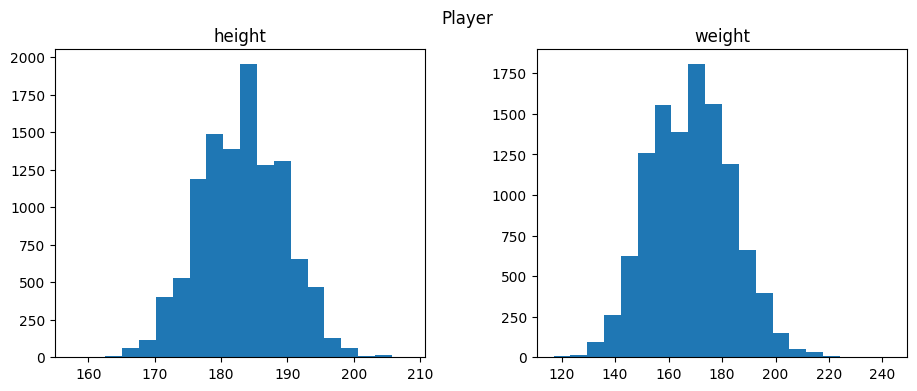

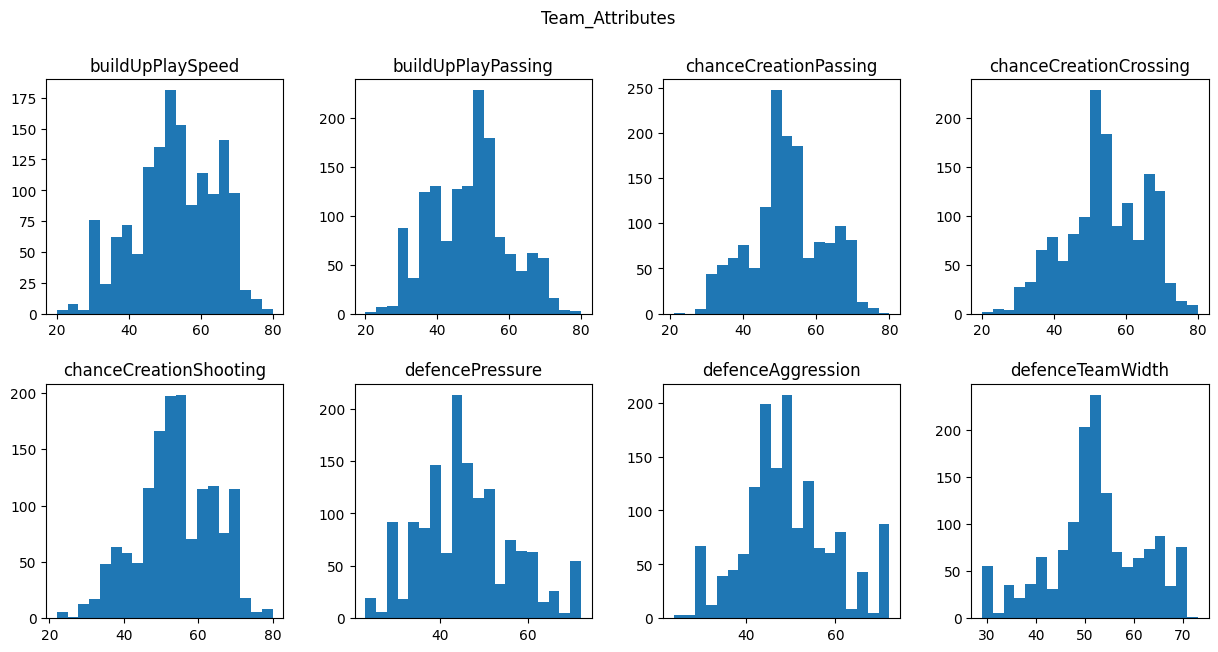

In [ ]:
# 3.a Histogramas de Player y Team_Attributes
df_player_clean[num_player].hist(bins=20, grid=False, figsize=(11, 4), layout=(1, 2))
plt.suptitle('Player')
plt.show()

df_team_attr_clean[num_team_attr].hist(bins=20, grid=False, figsize=(15, 7), layout=(2, 4))
plt.suptitle('Team_Attributes')
plt.show()

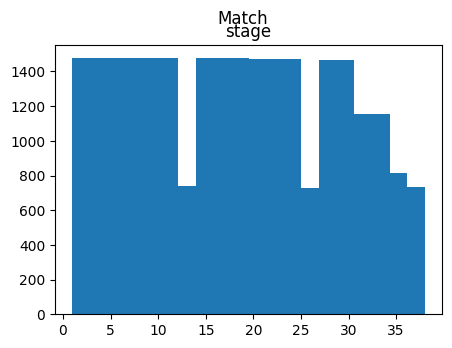

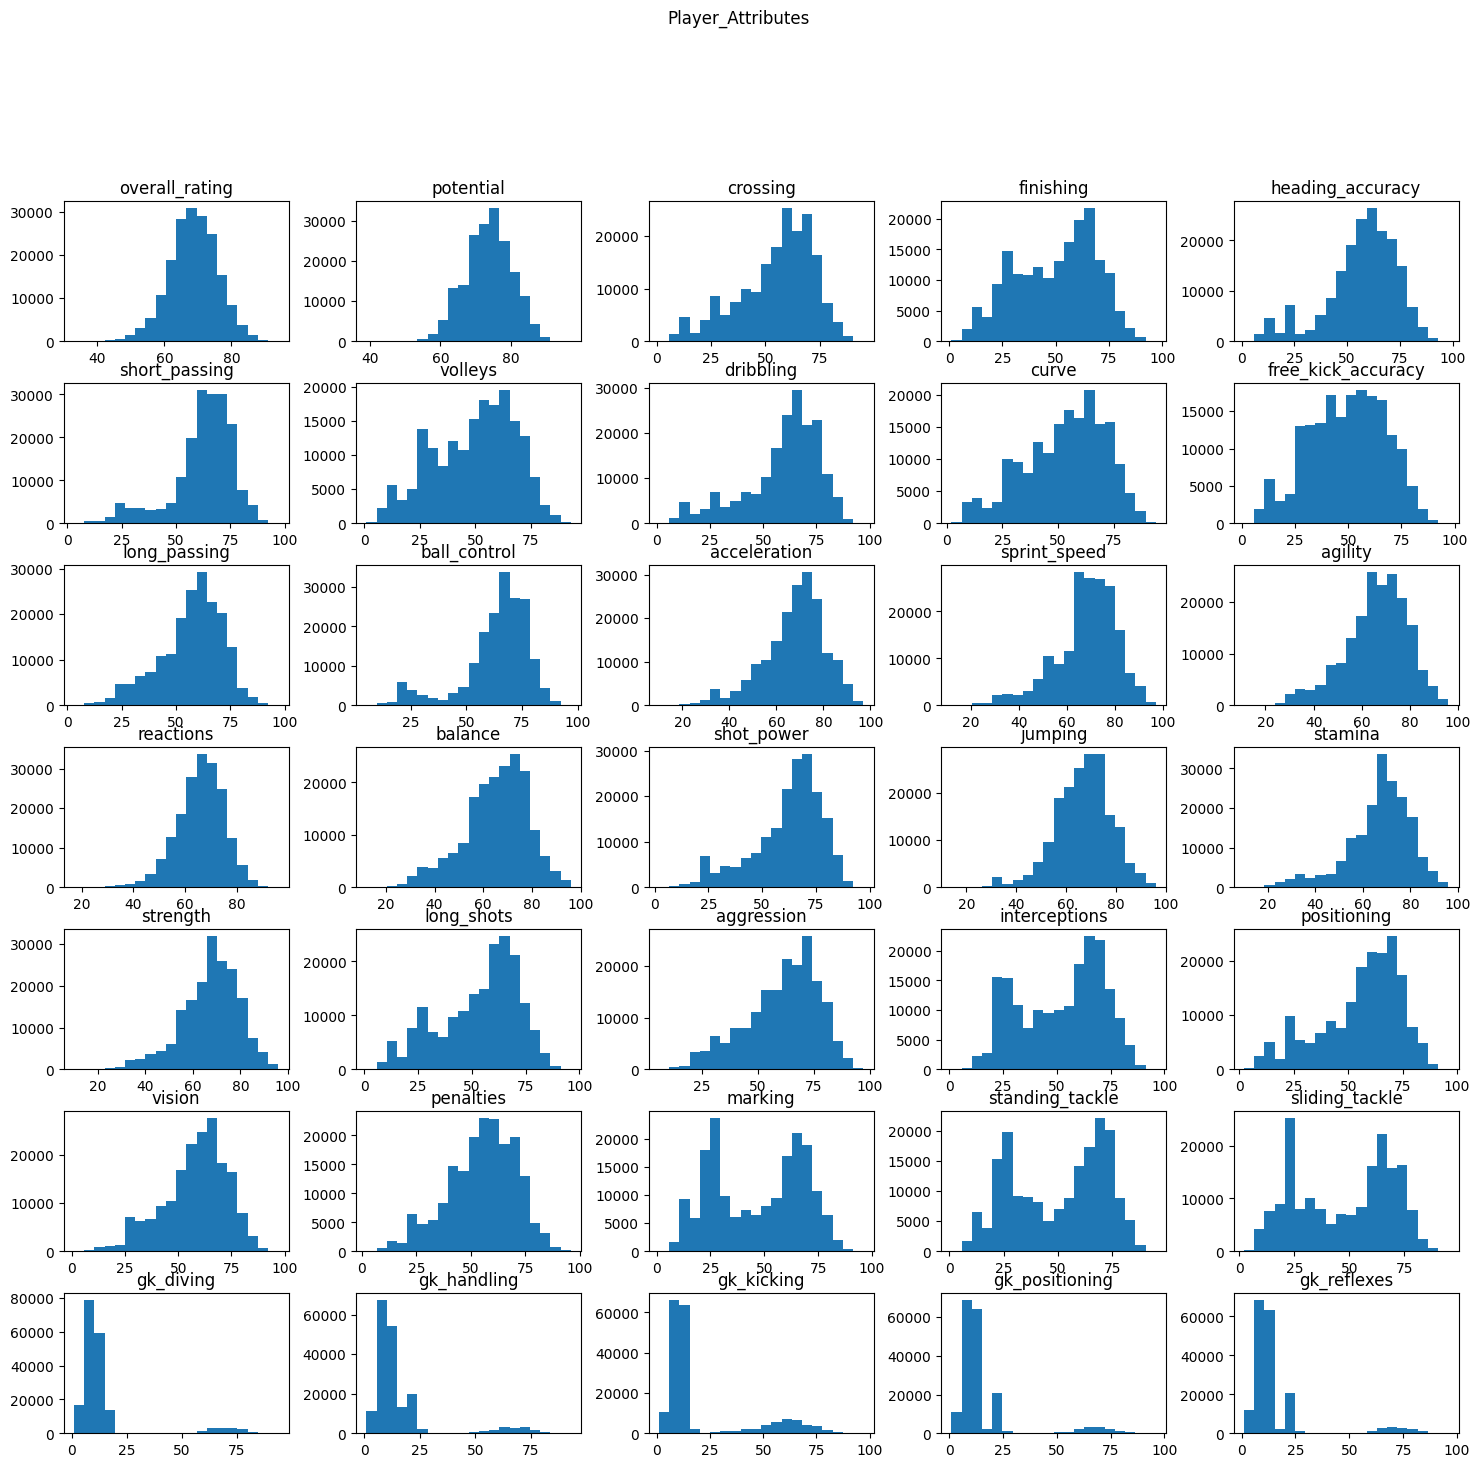

In [ ]:
# 3.a Histogramas de Match y de Player_Attributes (35 variables)
df_match_clean[num_match].hist(bins=20, grid=False, figsize=(5, 3.5))
plt.suptitle('Match')
plt.show()

df_player_attr_clean[num_player_attr].hist(bins=20, grid=False, figsize=(18, 16), layout=(7, 5))
plt.suptitle('Player_Attributes', y=1.0)
plt.show()

In [ ]:
# 3.a Prueba de normalidad de Kolmogorov-Smirnov, con asimetría y curtosis como apoyo
from scipy.stats import kstest


def prueba_normalidad(df, num_vars, nombre):
    print(f"===== {nombre} =====")
    for num in num_vars:
        serie = df[num].dropna()
        __, p_value = kstest(serie, 'norm', args=(serie.mean(), serie.std()))
        forma = ('aprox. normal' if abs(serie.skew()) < 0.5 and abs(serie.kurt()) < 1
                 else 'no normal')
        veredicto_ks = 'no se rechaza H0' if p_value > 0.05 else 'se rechaza H0'
        print(f"{num:<22} asimetría={serie.skew():6.2f}  curtosis={serie.kurt():6.2f}  "
              f"p={p_value:.3g} ({veredicto_ks:<16})  ->  {forma}")
    print()


prueba_normalidad(df_player_clean, num_player, "Player")
prueba_normalidad(df_team_attr_clean, num_team_attr, "Team_Attributes")
prueba_normalidad(df_match_clean, num_match, "Match")
prueba_normalidad(df_player_attr_clean, num_player_attr, "Player_Attributes")

===== Player =====
height                 asimetría= -0.01  curtosis= -0.17  p=2.57e-85 (se rechaza H0   )  ->  aprox. normal
weight                 asimetría=  0.18  curtosis=  0.05  p=1.23e-34 (se rechaza H0   )  ->  aprox. normal

===== Team_Attributes =====
buildUpPlaySpeed       asimetría= -0.27  curtosis= -0.56  p=0.000132 (se rechaza H0   )  ->  aprox. normal
buildUpPlayPassing     asimetría=  0.12  curtosis= -0.44  p=0.000125 (se rechaza H0   )  ->  aprox. normal
chanceCreationPassing  asimetría= -0.03  curtosis= -0.42  p=9.63e-08 (se rechaza H0   )  ->  aprox. normal
chanceCreationCrossing asimetría= -0.21  curtosis= -0.50  p=7.16e-06 (se rechaza H0   )  ->  aprox. normal
chanceCreationShooting asimetría= -0.18  curtosis= -0.22  p=7.2e-07 (se rechaza H0   )  ->  aprox. normal
defencePressure        asimetría=  0.34  curtosis= -0.19  p=5.06e-09 (se rechaza H0   )  ->  aprox. normal
defenceAggression      asimetría=  0.22  curtosis= -0.10  p=1.74e-09 (se rechaza H0   )  ->  apro

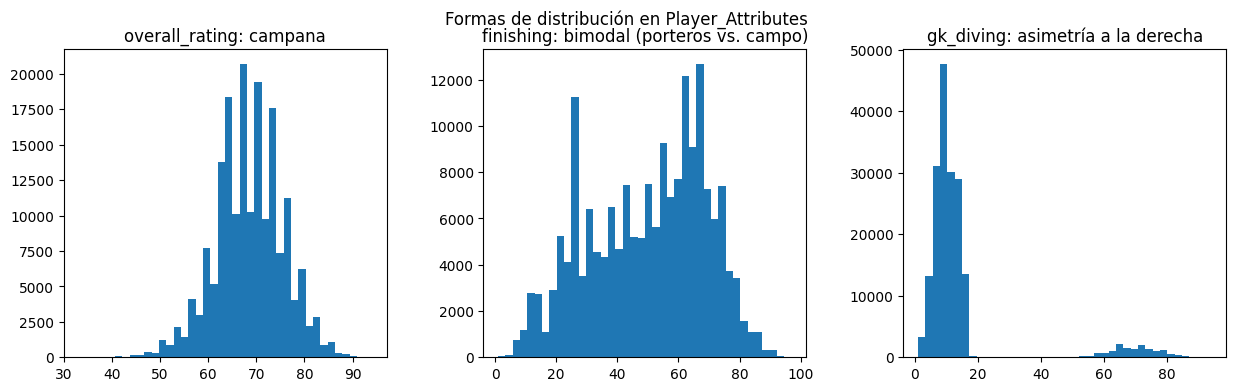

In [ ]:
# 3.a Tres casos representativos: campana, bimodal y asimétrica
fig, ax = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(15, 4)
    )
fig.suptitle('Formas de distribución en Player_Attributes')
df_player_attr_clean.hist('overall_rating', bins=40, grid=False, ax=ax[0])
ax[0].title.set_text('overall_rating: campana')
df_player_attr_clean.hist('finishing', bins=40, grid=False, ax=ax[1])
ax[1].title.set_text('finishing: bimodal (porteros vs. campo)')
df_player_attr_clean.hist('gk_diving', bins=40, grid=False, ax=ax[2])
ax[2].title.set_text('gk_diving: asimetría a la derecha')
plt.show()

**Resultados de 3.a.**

*Aproximadamente normales* (forma de campana, |asimetría| < 0,5 y |curtosis| < 1):

- `Player`: `height` (asimetría −0,01) y `weight` (0,18).
- `Team_Attributes`: las ocho variables tácticas numéricas (`buildUpPlaySpeed`, `buildUpPlayPassing`, `chanceCreationPassing`, `chanceCreationCrossing`, `chanceCreationShooting`, `defencePressure`, `defenceAggression`, `defenceTeamWidth`), todas con |asimetría| ≤ 0,35.
- `Player_Attributes`: `overall_rating` (−0,20), `potential` (−0,04) y `reactions` (−0,50).

*Con una distribución diferente*:

- **Bimodales por posición.** `finishing`, `volleys`, `curve`, `free_kick_accuracy`, `penalties`, `marking`, `standing_tackle`, `sliding_tackle` e `interceptions` tienen asimetría pequeña porque **el histograma muestra dos picos**: uno de jugadores de campo y otro, en valores muy bajos, de porteros. En las cinco primeras el criterio numérico llega a clasificarlas como aproximadamente normales (|asimetría| < 0,5 y |curtosis| < 1), que es justamente el caso en el que **el histograma manda sobre las medidas**; en las cuatro últimas la curtosis muy negativa (entre −1,16 y −1,40) ya delata por sí sola que la distribución es plana y con dos modas, no una campana.
- **Fuertemente asimétricas a la derecha.** Los cinco atributos de portero (`gk_diving`, `gk_handling`, `gk_kicking`, `gk_positioning`, `gk_reflexes`), con asimetría entre 1,5 y 3,0 y curtosis de hasta 7,4: la inmensa mayoría de las filas son jugadores de campo con valores cercanos a 10.
- **Asimétricas a la izquierda.** `ball_control` (−1,34), `short_passing` (−1,20) y `dribbling` (−1,01), que son atributos que casi todo futbolista profesional tiene alto.
- **Uniforme.** `stage` (la jornada) reparte los partidos casi por igual entre 1 y 38: asimetría 0,07 y curtosis −1,12, la firma de una distribución plana.

La prueba K-S rechaza la normalidad (`p < 0,05`) en **todas** las variables de las cuatro tablas, incluida `height`, que en el histograma es una campana de manual. Los p-valores más altos son los de `Team_Attributes`, que es la tabla más pequeña, y en `Player_Attributes` el p-valor es tan pequeño que en casi todas las variables aparece directamente como 0. Ese patrón es el efecto del tamaño de muestra que se anticipó arriba: cuantas más filas, más fácil le resulta a la prueba detectar desviaciones irrelevantes. Por eso el veredicto se apoya en la forma y las medidas, y el p-valor se usa solo como referencia.

### 3.b Identifiquen las variables con valores atípicos

Se usan diagramas de caja, en los que **los puntos por fuera de los bigotes son los valores atípicos**, y se cuantifica el porcentaje con la regla del rango intercuartílico vista en clase:

$$ IQR = Q3 - Q1, \qquad lower\_limit = Q1 - 1{,}5 \cdot IQR, \qquad upper\_limit = Q3 + 1{,}5 \cdot IQR $$

Se prefiere esta regla al criterio $|Z| > 3$ porque no supone normalidad, y aquí ya se sabe que la mayoría de las variables no son normales.

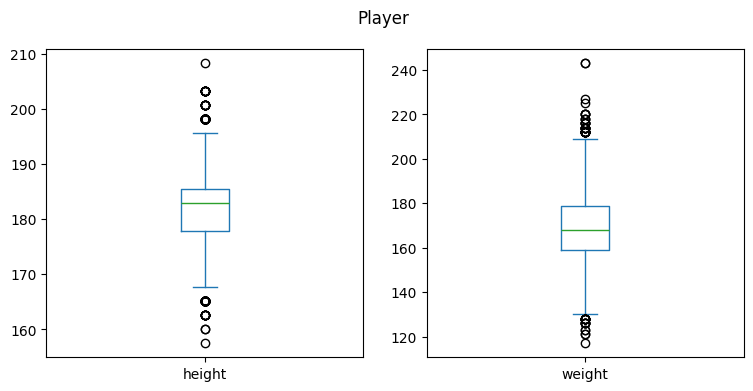

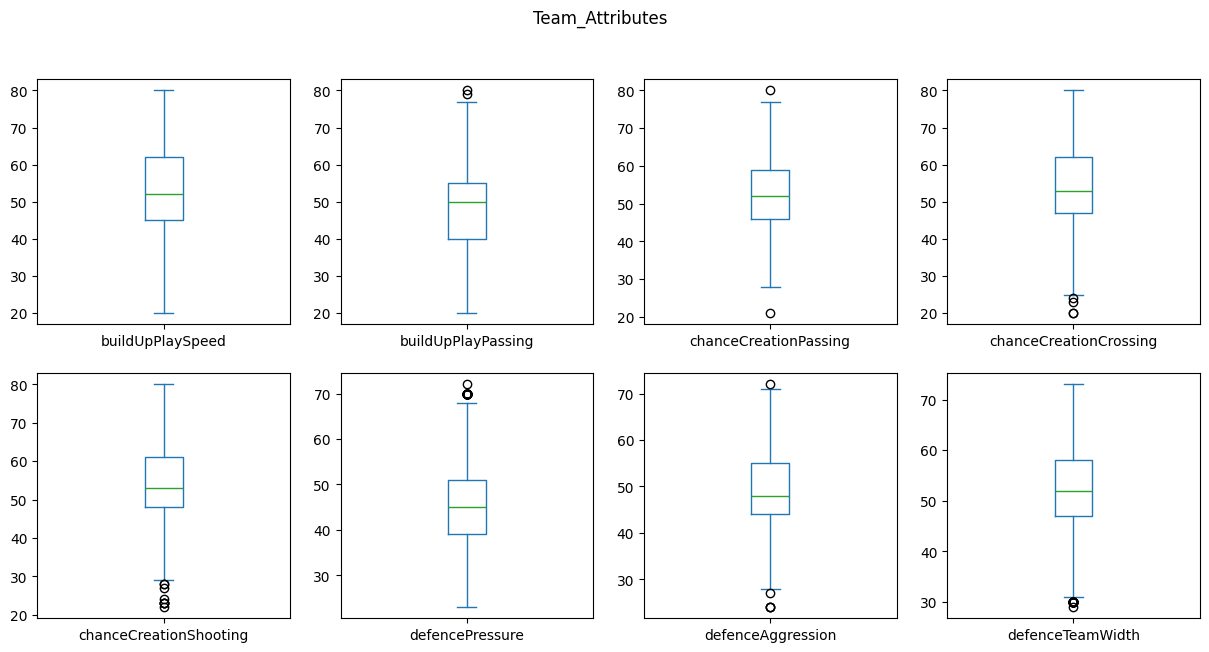

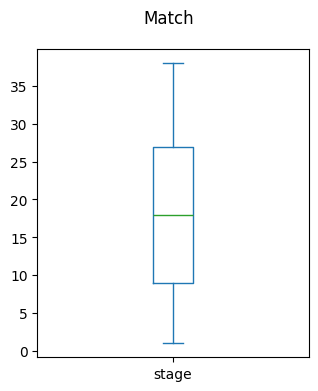

In [ ]:
# 3.b Diagramas de caja de Player, Team_Attributes y Match
df_player_clean[num_player].plot(kind='box', subplots=True, layout=(1, 2), figsize=(9, 4),
                                 sharex=False, sharey=False)
plt.suptitle('Player')
plt.show()

df_team_attr_clean[num_team_attr].plot(kind='box', subplots=True, layout=(2, 4), figsize=(15, 7),
                                       sharex=False, sharey=False)
plt.suptitle('Team_Attributes')
plt.show()

df_match_clean[num_match].plot(kind='box', subplots=True, layout=(1, 1), figsize=(3.5, 4),
                               sharex=False, sharey=False)
plt.suptitle('Match')
plt.show()

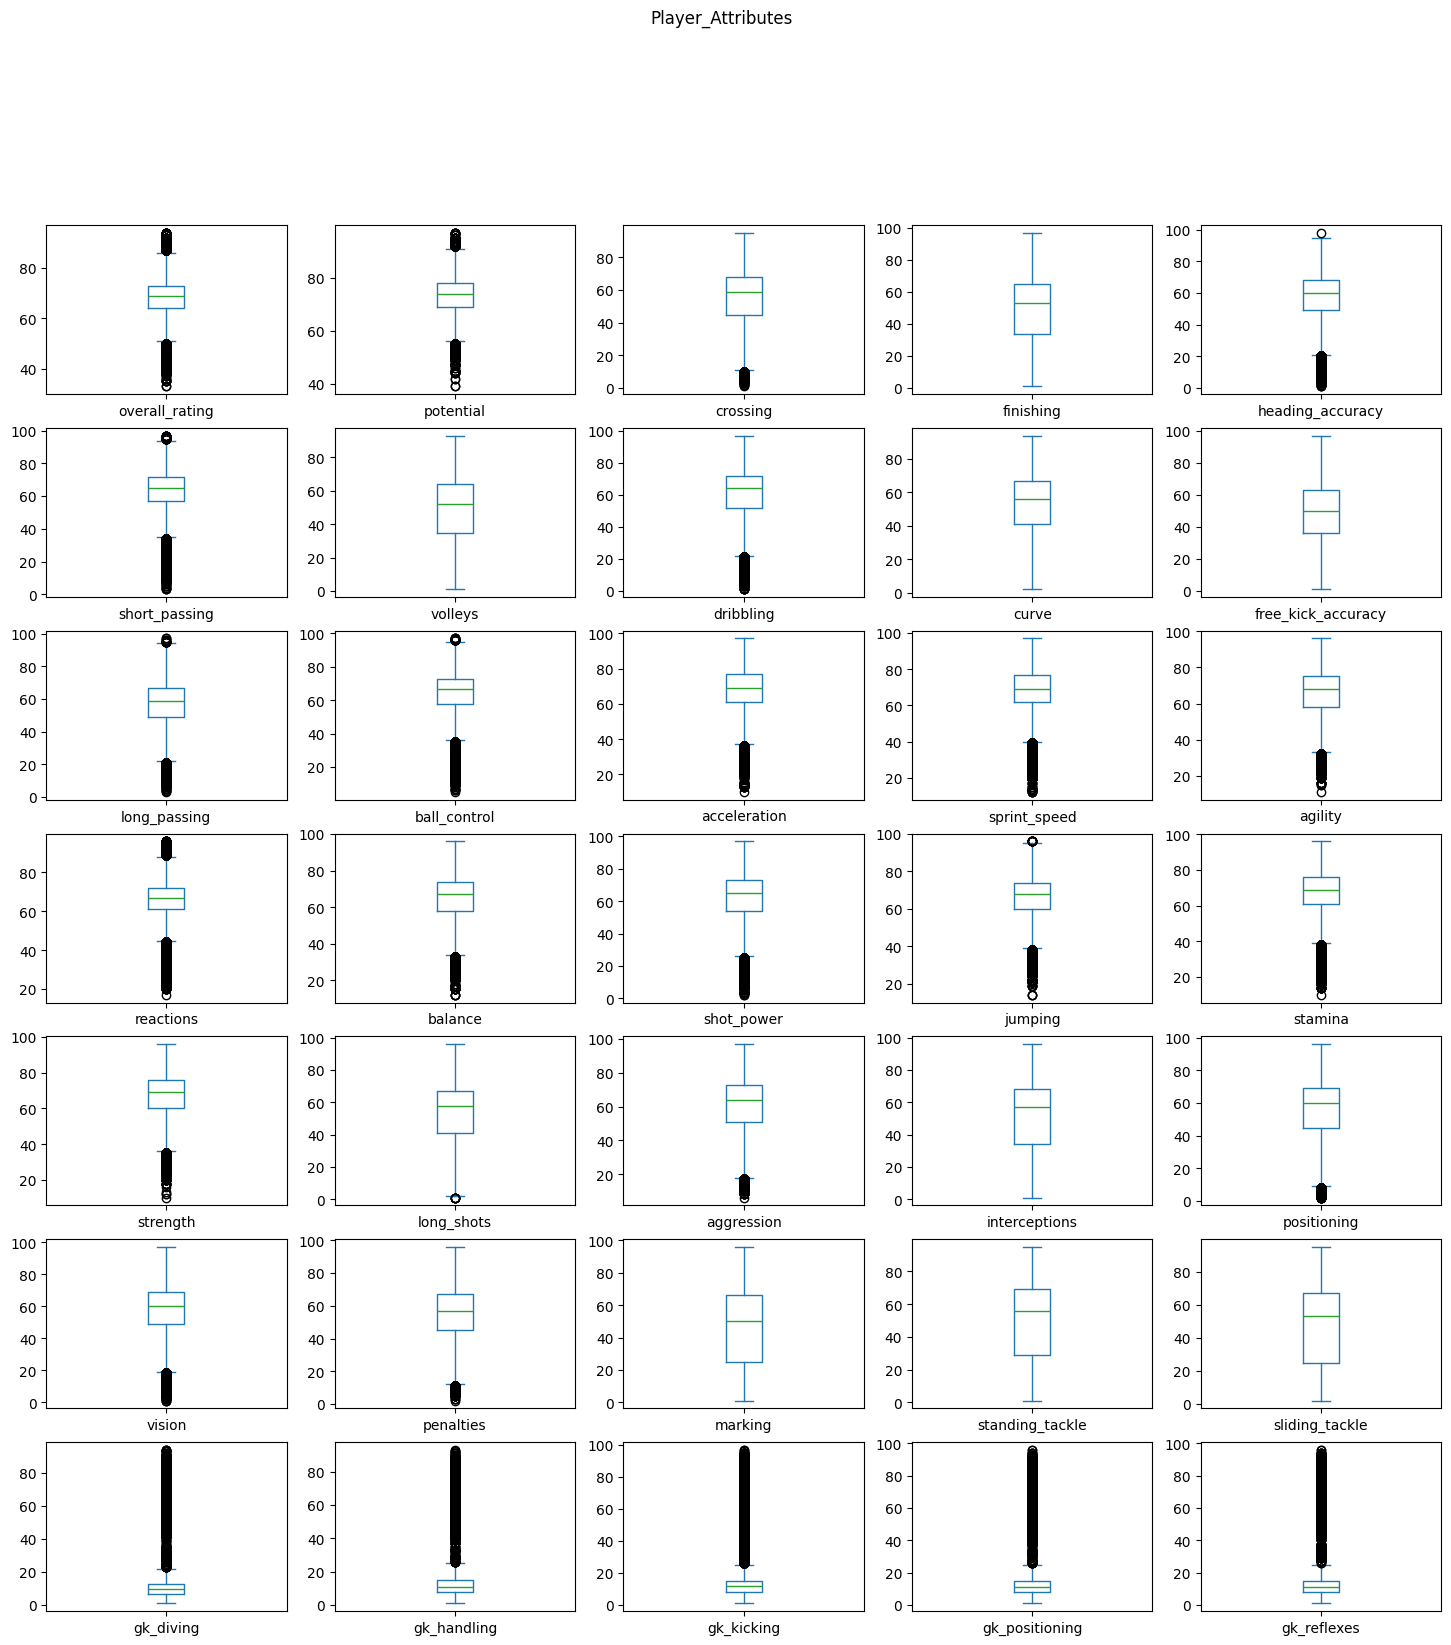

In [ ]:
# 3.b Diagramas de caja de Player_Attributes
df_player_attr_clean[num_player_attr].plot(kind='box', subplots=True, layout=(7, 5),
                                           figsize=(18, 18), sharex=False, sharey=False)
plt.suptitle('Player_Attributes', y=1.0)
plt.show()

In [ ]:
# 3.b Porcentaje de valores atípicos de cada variable, por la regla del IQR
def atipicos_iqr(df, num_vars, nombre):
    filas = []
    for num in num_vars:
        serie = df[num].dropna()
        Q1 = serie.quantile(0.25)
        Q3 = serie.quantile(0.75)
        IQR = Q3 - Q1
        upper_limit = Q3 + 1.5 * IQR
        lower_limit = Q1 - 1.5 * IQR
        atipicos = serie[(serie > upper_limit) | (serie < lower_limit)]
        filas.append({'variable': num, 'tabla': nombre,
                      '%_atipicos': len(atipicos) / len(serie) * 100})
    return pd.DataFrame(filas).set_index('variable')


atipicos = pd.concat([atipicos_iqr(df_player_clean, num_player, 'Player'),
                      atipicos_iqr(df_team_attr_clean, num_team_attr, 'Team_Attributes'),
                      atipicos_iqr(df_match_clean, num_match, 'Match'),
                      atipicos_iqr(df_player_attr_clean, num_player_attr, 'Player_Attributes')])

print("Variables CON valores atípicos (ordenadas de mayor a menor):")
display(atipicos[atipicos['%_atipicos'] > 0].sort_values('%_atipicos', ascending=False).round(2))

print("Variables SIN ningún valor atípico:")
print(atipicos[atipicos['%_atipicos'] == 0].index.tolist())

Variables CON valores atípicos (ordenadas de mayor a menor):


,tabla,%_atipicos
variable,,
gk_kicking,Player_Attributes,21.95
ball_control,Player_Attributes,8.47
gk_diving,Player_Attributes,8.24
gk_reflexes,Player_Attributes,8.21
gk_positioning,Player_Attributes,8.20
gk_handling,Player_Attributes,8.19
short_passing,Player_Attributes,7.21
dribbling,Player_Attributes,5.06
shot_power,Player_Attributes,5.05


Variables SIN ningún valor atípico:
['buildUpPlaySpeed', 'stage', 'finishing', 'volleys', 'curve', 'free_kick_accuracy', 'interceptions', 'marking', 'standing_tackle', 'sliding_tackle']


In [ ]:
# 3.b ¿Los atípicos de overall_rating son errores de captura o son los mejores del mundo?
serie = df_player_attr_clean['overall_rating'].dropna()
Q1 = serie.quantile(0.25)
Q3 = serie.quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
extremos = df_player_attr_clean[df_player_attr_clean['overall_rating'] > upper_limit]

print(f"Límite superior IQR de overall_rating: {upper_limit:.1f}")
print(f"Filas por encima del límite: {len(extremos)} ({len(extremos) / len(serie) * 100:.2f}%)")
print(f"Rango de valoración de esas filas: {extremos['overall_rating'].min():.0f} a "
      f"{extremos['overall_rating'].max():.0f}")

# y los atípicos bajos de un atributo dependiente de posición, ¿quiénes son?
print()
print("Valoración de portero (gk_reflexes) de las filas con 'finishing' más bajo:")
display(df_player_attr_clean.sort_values('finishing')[['finishing', 'gk_reflexes',
                                                       'overall_rating']].head(5))

Límite superior IQR de overall_rating: 86.5
Filas por encima del límite: 643 (0.35%)
Rango de valoración de esas filas: 87 a 94

Valoración de portero (gk_reflexes) de las filas con 'finishing' más bajo:


,finishing,gk_reflexes,overall_rating
146756,1.0,77.0,78.0
17778,1.0,64.0,62.0
133164,1.0,74.0,77.0
113202,1.0,71.0,68.0
135343,1.0,78.0,76.0


**Resultados de 3.b.** Prácticamente todas las variables tienen valores atípicos por la regla del IQR, pero su origen es distinto y eso es lo que determina el tratamiento:

| Variable(s) | % atípicos | ¿Qué son en realidad? |
|---|---|---|
| `gk_kicking` | 21,9 % | jugadores de campo dentro de una variable de portero |
| `ball_control`, `short_passing`, `dribbling`, `shot_power` | 5 % – 8,5 % | la cola baja son porteros |
| `gk_diving`, `gk_handling`, `gk_positioning`, `gk_reflexes` | ≈ 8,2 % | la cola alta son los porteros de verdad |
| `defencePressure`, `defenceTeamWidth` | ≈ 3,7 % | planteamientos tácticos extremos (presión muy alta, equipo muy abierto) |
| `overall_rating` | 1,3 % | las dos colas; por encima del límite superior (86,5) quedan 643 registros de la élite mundial |
| `height`, `weight` | 1,4 % y 0,6 % | porteros y centrales altos, extremos ligeros |
| `stage`, `finishing`, `volleys`, `curve`, `marking`, `standing_tackle`, `sliding_tackle`, `interceptions`, `free_kick_accuracy`, `buildUpPlaySpeed` | 0 % | no tienen atípicos: son las variables planas o bimodales, cuyas dos modas ensanchan tanto el IQR que nada queda fuera de los bigotes |

La comprobación explícita confirma la lectura: el límite superior del IQR de `overall_rating` está en 86,5 y las 643 filas que lo superan tienen valoraciones de 87 a 94, es decir, son los mejores futbolistas del mundo y no errores de digitación; y las filas con `finishing` mínimo (1 punto) tienen `gk_reflexes` alto, o sea, son porteros.

En consecuencia **no se elimina ninguna fila por ser atípica**. Eliminarlas borraría justo la señal que distingue a un plantel de élite de uno medio. La respuesta correcta es de escalamiento (usar mediana e IQR donde las colas pesan), y se aplica en 3.c.

### 3.c Indiquen qué tipo de tratamiento debería recibir cada variable numérica

| Grupo de variables | Distribución | Atípicos | Tratamiento |
|---|---|---|---|
| `height`, `weight` (`Player`) | aproximadamente normales | pocos y plausibles | **StandardScaler**: es el escalador indicado cuando la variable es simétrica y no hay colas pesadas |
| `overall_rating`, `potential`, `reactions` (`Player_Attributes`) | aproximadamente normales | 0,5 % – 2 %, son la élite | **StandardScaler**, aplicado sobre el promedio de los once titulares (ver punto 4) |
| Ocho atributos tácticos numéricos de `Team_Attributes` | simétricas, acotadas por construcción entre 20 y 80 | < 1 %, salvo `defencePressure` y `defenceTeamWidth` (≈ 3,7 %) | **StandardScaler** en general y **RobustScaler** en las que conserven atípicos. Aunque ya son comparables entre sí, deben escalarse porque conviven con variables en otras unidades (valoración, jornada) |
| `stage` (`Match`) | uniforme entre 1 y 38 | ninguno | **StandardScaler**. No es normal, pero al no tener colas ni atípicos basta con centrarla y escalarla |
| Atributos bimodales por posición (`finishing`, `marking`, `standing_tackle`, `sliding_tackle`, `volleys`, `curve`, `interceptions`…) | **bimodales** | los marcados son porteros | **Ninguna transformación monótona corrige una bimodalidad**: ni logaritmo ni `PowerTransformer` juntan dos modas. No entran crudos al modelo; la calidad del jugador se resume con `overall_rating` y `potential`, y **el promedio de los once titulares elimina la bimodalidad**, porque promediar once jugadores devuelve una distribución unimodal y casi simétrica |
| `gk_diving`, `gk_handling`, `gk_kicking`, `gk_positioning`, `gk_reflexes` | asimetría derecha extrema | hasta 21,9 % | Se **excluyen** del modelo. Su información útil, la calidad del portero titular, ya viaja dentro del `overall_rating` de ese jugador |
| `ball_control`, `short_passing`, `dribbling` y demás atributos técnicos | asimetría a la izquierda | 5 % – 8,5 % | Igual que los anteriores: no entran crudos, se resumen en el promedio de la alineación |
| Coordenadas `home_player_X*` / `_Y*` e identificadores | discretas o categóricas | no aplica | **Fuera del modelo**, según el alcance definido en la Entrega 1. Además, la coordenada del portero es prácticamente constante y una variable de varianza cero rompe el escalamiento |
| Cuotas `B365H`, `B365D`, `B365A` | asimetría derecha fuerte (≈ 9 % de atípicos) | sí | **Fuera del modelo**: se apartaron en 1.g como *benchmark* de mercado para la Entrega 3, no como características |

**Regla que se aplicará en el punto 4.** Las variables que entran de verdad al modelo no son las columnas crudas de estas tablas, sino las **derivadas a nivel de partido** (perfil táctico de cada equipo y promedio de la alineación). Por eso el mismo diagnóstico de 3.a y 3.b se repite en 4.d sobre la matriz de características ya construida y **solo con los datos de entrenamiento**, y con el resultado se reparten las variables entre `StandardScaler` (simétricas y sin atípicos relevantes) y `RobustScaler` (asimétricas o con más de 1 % de atípicos).

### 3.d Reporten los resultados de los análisis en una celda de texto

**Hallazgos (variables numéricas).** Las variables numéricas de la fuente se reparten en tres perfiles claramente distintos.

El primero son las **variables acampanadas**: `overall_rating`, `potential`, `reactions`, `height`, `weight` y los ocho atributos tácticos de equipo. Tienen media y mediana casi iguales y asimetría por debajo de 0,5 en valor absoluto. La prueba de Kolmogorov-Smirnov las rechaza igual que a todas las demás, pero eso es un artefacto del tamaño de muestra: con 180.000 filas cualquier desviación mínima resulta significativa, y por eso el veredicto se apoya en el histograma, la asimetría y la curtosis. Estas variables reciben escalamiento estándar.

El segundo perfil, y el hallazgo más importante del punto, son las **variables bimodales por posición**: `finishing`, `marking`, `standing_tackle`, `sliding_tackle`, `volleys`, `curve` y sobre todo los cinco atributos `gk_*` no son distribuciones asimétricas que se arreglen con un logaritmo o una transformación de potencia, sino **mezclas de dos poblaciones** —porteros y jugadores de campo— dentro de una misma columna. Un `gk_diving` de 8 no es un dato atípico ni un error: es un delantero. Como ninguna transformación monótona junta esas dos modas, la decisión no es transformar sino **cambiar el nivel de análisis**: el modelo trabaja con el promedio de los once titulares, y promediar once jugadores devuelve una distribución unimodal y aproximadamente simétrica.

El tercer perfil son las **variables acotadas por construcción**: los ocho atributos tácticos de `Team_Attributes` viven en una escala de 20 a 80 con escalones discretos justo en los umbrales de sus variables `*Class`, y `stage` es prácticamente uniforme. No son normales, pero tampoco tienen colas largas, así que el escalamiento estándar es suficiente, salvo donde el porcentaje de atípicos aconseje el escalador robusto.

Sobre los **valores atípicos**, la regla del IQR marca sobre todo la cola alta de `overall_rating` (jugadores de 87 a 94 puntos) y la cola baja de los atributos dependientes de posición (porteros). En ambos casos son atípicos **estructurales y legítimos**, no errores de captura, así que no se elimina ninguna fila: recortarlos borraría la señal que distingue a un plantel de élite de uno medio. La respuesta es de escalamiento —mediana e IQR donde las colas pesan— y no de recorte. Las coordenadas de alineación y las cuotas quedan fuera del análisis por las decisiones de alcance tomadas en la Entrega 1 y en el punto 1.g.

# 4. Procesamiento de las características y entrenamiento del modelo

> **Enunciado de la entrega**
> 1. Escojan un modelo adecuado al tipo de variable que van a predecir (modelo de clasificación o de regresión).
> 2. Extraigan la matriz de características y el vector objetivo de su dataframe, a partir de los análisis previos.
> 3. Partan los datos en subconjuntos de entrenamiento y de prueba.
> 4. Procesen las características del modelo usando ColumnTransformer.
> 5. Creen un flujo de trabajo con Pipeline.
> 6. Entrenen el modelo.
> 7. Reporten los scores de entrenamiento y de prueba.
> 8. Reporten el listado completo de características con las que fue entrenado el modelo después del procesamiento realizado.

Cada numeral se resuelve en su propia sección: **4.a** a **4.h**.

Hasta aquí cada tabla se analizó por separado. Para entrenar hace falta **un solo dataframe**, con una fila por partido, la variable objetivo y solo información disponible antes del partido. Ese dataframe se arma en 4.b uniendo con `merge` los dos bloques de predictores definidos en la Entrega 1:

1. **Perfil táctico del equipo** (`Team_Attributes`): cómo juega cada club.
2. **Calidad de la plantilla alineada** (`Match` → `Player_Attributes`): la valoración media de los once titulares de cada lado, que es además la solución a la bimodalidad diagnosticada en 3.a y 3.c.

Las dos uniones resumen primero la tabla de origen a **una fila por equipo** y **una fila por jugador** (con `drop_duplicates` y con `groupby`), y solo entonces se unen a `Match` con un `merge` normal. Es una simplificación consciente: se usa el perfil táctico más reciente del club y la valoración media histórica del jugador, en lugar de la vigente en la fecha exacta de cada partido. Ninguna de las dos se calcula a partir del marcador que se quiere predecir, así que no hay fuga de la variable objetivo, pero sí conviene afinarlo en la Entrega 3.

### 4.a Escojan un modelo adecuado al tipo de variable que van a predecir

La variable objetivo `resultado` toma **tres valores sin orden entre sí** (`victoria_local`, `empate`, `victoria_visitante`), así que el problema es de **clasificación multiclase**, no de regresión.

Se entrena una **regresión logística** (`LogisticRegression`), que es el modelo de clasificación usado en clase y la línea base prevista en el objetivo específico 2 de la Entrega 1. Se elige por tres razones: entrega directamente **probabilidades** para las tres clases —que es el producto que el proyecto quiere vender, no una etiqueta seca—, sus coeficientes son interpretables por bloque de variables, y permite compararse contra el mercado de apuestas con la misma métrica en la Entrega 3. Con el solver por defecto (`lbfgs`), scikit-learn ajusta automáticamente la versión multinomial cuando `y` tiene más de dos clases.

In [ ]:
# 4.b.1 Dataframe base: una fila por partido, con la variable objetivo
df_modelo = df_match_clean[['match_api_id', 'league_id', 'season', 'stage',
                            'home_team_api_id', 'away_team_api_id', 'resultado']]
print("Partidos de partida:", df_modelo.shape)
df_modelo.head()

Partidos de partida: (25979, 7)


,match_api_id,league_id,season,stage,home_team_api_id,away_team_api_id,resultado
0,492473,1,2008/2009,1,9987,9993,empate
1,492474,1,2008/2009,1,10000,9994,empate
2,492475,1,2008/2009,1,9984,8635,victoria_visitante
3,492476,1,2008/2009,1,9991,9998,victoria_local
4,492477,1,2008/2009,1,7947,9985,victoria_visitante


In [ ]:
# 4.b.2 Bloque 1: perfil táctico de cada equipo.
#       Team_Attributes tiene varias fichas por club (una por temporada). Se ordenan por fecha y se
#       conserva la última de cada equipo, de modo que quede UNA fila por club: así la tabla se
#       puede unir a los partidos con un merge normal.
perfil_equipo = (df_team_attr_clean
                 .sort_values('date')
                 .drop_duplicates(subset=['team_api_id'], keep='last')
                 .drop(columns=['date']))
print("Fichas tácticas:", df_team_attr_clean.shape, " ->  perfil por equipo:", perfil_equipo.shape)

# se hacen dos copias con los nombres de columna prefijados, una para el equipo local y otra para
# el visitante, para poder unir las dos al mismo dataframe de partidos
perfil_local = perfil_equipo.copy()
perfil_local.columns = ['local_' + c for c in perfil_equipo.columns]

perfil_visitante = perfil_equipo.copy()
perfil_visitante.columns = ['visitante_' + c for c in perfil_equipo.columns]

df_modelo = df_modelo.merge(perfil_local, left_on='home_team_api_id',
                            right_on='local_team_api_id', how='left')
df_modelo = df_modelo.merge(perfil_visitante, left_on='away_team_api_id',
                            right_on='visitante_team_api_id', how='left')
df_modelo = df_modelo.drop(columns=['local_team_api_id', 'visitante_team_api_id'])

print("Dimensiones tras el bloque táctico:", df_modelo.shape)
print("Partidos sin perfil táctico del local: "
      f"{df_modelo['local_buildUpPlaySpeed'].isnull().mean() * 100:.1f}%")

Fichas tácticas: (1457, 22)  ->  perfil por equipo: (288, 21)
Dimensiones tras el bloque táctico: (25979, 47)
Partidos sin perfil táctico del local: 0.7%


In [ ]:
# 4.b.3 Bloque 2: calidad de la plantilla alineada.
#       Player_Attributes tiene varias valoraciones por jugador, así que primero se resume cada
#       jugador en su valoración media con groupby: eso deja UNA fila por jugador.
rating_jugador = (df_player_attr_clean
                  .groupby('player_api_id')[['overall_rating', 'potential']]
                  .mean()
                  .reset_index())

# las columnas de alineación de Match guardan el id del jugador como decimal (porque tienen nulos),
# así que se iguala el tipo de la llave antes de unir
rating_jugador['player_api_id'] = rating_jugador['player_api_id'].astype('float64')

print("Valoraciones:", df_player_attr_clean.shape, " ->  un rating por jugador:",
      rating_jugador.shape)
rating_jugador.head()

Valoraciones: (183142, 40)  ->  un rating por jugador: (11060, 3)


,player_api_id,overall_rating,potential
0,2625.0,60.142857,61.142857
1,2752.0,69.380952,70.380952
2,2768.0,69.285714,70.571429
3,2770.0,71.133333,73.533333
4,2790.0,70.200000,75.800000


In [ ]:
# 4.b.3 (cont.) Para cada partido se traen las valoraciones de los once titulares de un lado y se
#       promedian. Promediar once jugadores es lo que elimina la bimodalidad diagnosticada en 3.a.
cols_home = [f'home_player_{i}' for i in range(1, 12)]
cols_away = [f'away_player_{i}' for i in range(1, 12)]


def rating_de_la_alineacion(cols_titulares, prefijo):
    tabla = df_match_clean[['match_api_id']]
    for i, col in enumerate(cols_titulares, start=1):
        titular = df_match_clean[['match_api_id', col]].merge(
            rating_jugador, left_on=col, right_on='player_api_id', how='left')
        titular = titular[['match_api_id', 'overall_rating', 'potential']]
        titular.columns = ['match_api_id', f'rating_{i}', f'potencial_{i}']
        tabla = tabla.merge(titular, on='match_api_id', how='left')

    resumen = tabla[['match_api_id']].copy()
    resumen[prefijo + '_rating_medio'] = tabla[[f'rating_{i}' for i in range(1, 12)]].mean(axis=1)
    resumen[prefijo + '_potencial_medio'] = tabla[[f'potencial_{i}' for i in range(1, 12)]].mean(axis=1)
    return resumen


df_modelo = df_modelo.merge(rating_de_la_alineacion(cols_home, 'local'),
                            on='match_api_id', how='left')
df_modelo = df_modelo.merge(rating_de_la_alineacion(cols_away, 'visitante'),
                            on='match_api_id', how='left')

print("Dimensiones tras el bloque de plantilla:", df_modelo.shape)
display(df_modelo[['local_rating_medio', 'visitante_rating_medio',
                   'local_potencial_medio', 'visitante_potencial_medio']].describe().round(2))

Dimensiones tras el bloque de plantilla: (25979, 51)


,local_rating_medio,visitante_rating_medio,local_potencial_medio,visitante_potencial_medio
count,25221.00,25221.00,25221.00,25221.00
mean,70.32,70.25,74.26,74.21
std,5.31,5.30,5.07,5.06
min,54.89,55.12,59.41,59.41
25%,66.33,66.28,70.54,70.56
50%,70.82,70.68,74.77,74.70
75%,73.75,73.65,77.68,77.62
max,84.92,85.05,87.74,87.92


In [ ]:
# 4.b.4 Gestión de nulos del dataframe de modelado.
#       Los nulos vienen de dos sitios: clubes sin ficha en Team_Attributes y partidos sin
#       alineación registrada (el faltante ligado a liga y temporada que se documentó en 1.e).
#       Se eliminan las filas incompletas en vez de imputar, porque imputar cuarenta columnas
#       tácticas a la vez crearía un bloque artificial enorme, y porque la eliminación deja
#       igualmente ocho temporadas con partidos suficientes.
print("% de nulos por columna, antes de la limpieza:")
nulos = df_modelo.isnull().sum() / df_modelo.shape[0] * 100
print(nulos[nulos > 0].sort_values(ascending=False).round(2).head(10))

antes = df_modelo.shape[0]
df_modelo = df_modelo.dropna()
df_modelo = df_modelo.reset_index(drop=True)
print(f"\nPartidos utilizables: {antes} -> {df_modelo.shape[0]}")
print("Nulos que quedan en el dataframe:", df_modelo.isnull().sum().sum())

print("\nPartidos por temporada:")
print(df_modelo['season'].value_counts().sort_index())

% de nulos por columna, antes de la limpieza:
local_rating_medio                   2.92
local_potencial_medio                2.92
visitante_rating_medio               2.92
visitante_potencial_medio            2.92
local_buildUpPlayPassingClass        0.69
local_buildUpPlayPositioningClass    0.69
local_chanceCreationPassing          0.69
local_chanceCreationPassingClass     0.69
local_buildUpPlaySpeed               0.69
local_buildUpPlaySpeedClass          0.69
dtype: float64

Partidos utilizables: 25979 -> 24967
Nulos que quedan en el dataframe: 0

Partidos por temporada:
season
2008/2009    2506
2009/2010    3230
2010/2011    3230
2011/2012    3190
2012/2013    3260
2013/2014    3032
2014/2015    3325
2015/2016    3194
Name: count, dtype: int64


In [ ]:
# 4.b.5 Matriz de características (X) y vector objetivo (y)
# fuera de X: las llaves, la temporada (contexto, no predictor) y la propia variable objetivo
X = df_modelo.drop(
    ['match_api_id', 'season', 'resultado', 'home_team_api_id', 'away_team_api_id'],
    axis=1
    )

y = df_modelo['resultado']

print("X:", X.shape, "| y:", y.shape)
print("\nDistribución de la variable objetivo:")
print(y.value_counts(normalize=True).round(3))

X: (24967, 46) | y: (24967,)

Distribución de la variable objetivo:
resultado
victoria_local        0.458
victoria_visitante    0.288
empate                0.254
Name: proportion, dtype: float64


In [ ]:
# 4.b.6 Tipos de variable dentro de X, según los análisis de los puntos 2 y 3.
# Cada *Class de Team_Attributes es una discretización de su propia variable numérica
# (buildUpPlaySpeedClass sale de aplicar umbrales a buildUpPlaySpeed): incluir ambas duplicaría la
# misma información y solo añadiría colinealidad, así que se conserva la numérica, que es más fina.
clases_redundantes = [f'{lado}_{c}' for lado in ('local', 'visitante') for c in
                      ['buildUpPlaySpeedClass', 'buildUpPlayPassingClass',
                       'chanceCreationPassingClass', 'chanceCreationCrossingClass',
                       'chanceCreationShootingClass', 'defencePressureClass',
                       'defenceAggressionClass', 'defenceTeamWidthClass']]
X = X.drop(clases_redundantes, axis=1)

# sobreviven las categóricas SIN equivalente numérico:
#  - buildUpPlayDribblingClass: ordinal (Little < Normal < Lots, punto 2.a); su columna numérica se
#    eliminó en 1.h por tener más del 50% de nulos, así que la clase es la única fuente
#  - las tres de estilo (posicionamiento y línea defensiva): nominales puras, sin numérica detrás
cat_ordinales = [f'{lado}_buildUpPlayDribblingClass' for lado in ('local', 'visitante')]
cat_nominales = [f'{lado}_{c}' for lado in ('local', 'visitante') for c in
                 ['buildUpPlayPositioningClass', 'chanceCreationPositioningClass',
                  'defenceDefenderLineClass']] + ['league_id']

X['league_id'] = X['league_id'].astype(str)   # es un identificador de categoría, no una magnitud
num_features = [c for c in X.columns if c not in cat_ordinales + cat_nominales]

print(f"X final: {X.shape[1]} columnas -> {len(num_features)} numéricas, "
      f"{len(cat_ordinales)} ordinales, {len(cat_nominales)} nominales")
print("\nNuméricas:", num_features)
print("\nOrdinales:", cat_ordinales)
print("\nNominales:", cat_nominales)

X final: 30 columnas -> 21 numéricas, 2 ordinales, 7 nominales

Numéricas: ['stage', 'local_buildUpPlaySpeed', 'local_buildUpPlayPassing', 'local_chanceCreationPassing', 'local_chanceCreationCrossing', 'local_chanceCreationShooting', 'local_defencePressure', 'local_defenceAggression', 'local_defenceTeamWidth', 'visitante_buildUpPlaySpeed', 'visitante_buildUpPlayPassing', 'visitante_chanceCreationPassing', 'visitante_chanceCreationCrossing', 'visitante_chanceCreationShooting', 'visitante_defencePressure', 'visitante_defenceAggression', 'visitante_defenceTeamWidth', 'local_rating_medio', 'local_potencial_medio', 'visitante_rating_medio', 'visitante_potencial_medio']

Ordinales: ['local_buildUpPlayDribblingClass', 'visitante_buildUpPlayDribblingClass']

Nominales: ['local_buildUpPlayPositioningClass', 'local_chanceCreationPositioningClass', 'local_defenceDefenderLineClass', 'visitante_buildUpPlayPositioningClass', 'visitante_chanceCreationPositioningClass', 'visitante_defenceDefenderLineC

### 4.c Partan los datos en subconjuntos de entrenamiento y de prueba

Se parte con `train_test_split` en una relación **80/20** y con `random_state=1`, igual que en el taller, de modo que la partición sea reproducible al ejecutar el notebook de nuevo.

Se deja constancia de una decisión metodológica: en la Entrega 3, cuando el modelo se compare contra las cuotas del mercado, la partición deberá volverse **temporal** (entrenar con las temporadas viejas y probar con las dos últimas), porque el uso real del modelo es predecir la próxima jornada con lo ya ocurrido y una partición aleatoria mezcla partidos de mayo con partidos de agosto de la misma temporada. Para esta entrega, cuyo objetivo es el flujo de preprocesamiento, se usa la partición aleatoria vista en clase.

In [ ]:
# 4.c Partición en entrenamiento (80%) y prueba (20%)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=1, train_size=0.8)

print(f'Tamaño del conjunto de entrenamiento es: {X_train.shape}')
print(f'Tamaño del conjunto de prueba es: {X_test.shape}')

print("\nDistribución del objetivo en cada conjunto:")
display(pd.DataFrame({'entrenamiento': y_train.value_counts(normalize=True),
                      'prueba': y_test.value_counts(normalize=True)}).round(3))

Tamaño del conjunto de entrenamiento es: (19973, 30)
Tamaño del conjunto de prueba es: (4994, 30)

Distribución del objetivo en cada conjunto:


,entrenamiento,prueba
resultado,,
victoria_local,0.457,0.462
victoria_visitante,0.289,0.286
empate,0.254,0.253


### 4.d Procesen las características del modelo usando ColumnTransformer

El `ColumnTransformer` tiene cuatro ramas, una por cada tipo de variable identificado en los puntos 2 y 3:

| Rama | Variables | Transformador | Por qué |
|---|---|---|---|
| `num_estandar` | numéricas simétricas y sin atípicos relevantes | `StandardScaler` | las deja con media 0 y varianza 1, que es lo adecuado cuando no hay colas pesadas |
| `num_robusto` | numéricas con \|asimetría\| > 0,5 o más de 1 % de atípicos | `RobustScaler` | usa mediana e IQR, así que las colas no arrastran el centro ni la escala |
| `ordinal` | `buildUpPlayDribblingClass` de cada equipo | `OrdinalEncoder` | es ordinal (`Little` < `Normal` < `Lots`), y el orden se pasa explícito para que la codificación lo respete |
| `nominal` | estilos tácticos sin orden y `league_id` | `OneHotEncoder` | son nominales de baja cardinalidad (2 categorías, y 11 en `league_id`); con `drop='if_binary'` se evita la columna redundante en las binarias |

El reparto entre las dos ramas numéricas **no se inventa**: se decide con el mismo diagnóstico de 3.a y 3.b (asimetría, curtosis y regla del IQR), aplicado ahora a las características derivadas y **solo sobre `X_train`**. Mirar también el conjunto de prueba para decidir el escalamiento sería una filtración de datos, igual que imputar antes de partir.

In [ ]:
# 4.d Diagnóstico de las características derivadas, calculado SOLO sobre el entrenamiento
diagnostico = pd.DataFrame({
    'asimetria': X_train[num_features].skew().round(2),
    'curtosis': X_train[num_features].kurt().round(2),
    '%_atipicos': atipicos_iqr(X_train, num_features, 'X_train')['%_atipicos'].round(2),
})

# se aplica el mismo criterio del punto 3: si la variable es asimétrica o tiene atípicos, el
# escalador debe ser robusto; si es simétrica y limpia, basta con el estándar
diagnostico['criterio'] = ['RobustScaler' if abs(a) > 0.5 or p > 1 else 'StandardScaler'
                           for a, p in zip(diagnostico['asimetria'], diagnostico['%_atipicos'])]

display(diagnostico.sort_values('asimetria', ascending=False))

,asimetria,curtosis,%_atipicos,criterio
local_defenceAggression,0.19,-0.15,0.29,StandardScaler
visitante_defenceAggression,0.18,-0.16,0.29,StandardScaler
visitante_defencePressure,0.15,-0.37,0.56,StandardScaler
local_defencePressure,0.14,-0.38,0.56,StandardScaler
stage,0.05,-1.13,0.00,StandardScaler
local_buildUpPlayPassing,0.04,-0.35,0.00,StandardScaler
visitante_buildUpPlayPassing,0.02,-0.32,0.08,StandardScaler
visitante_rating_medio,0.01,-0.47,0.07,StandardScaler
local_rating_medio,-0.01,-0.49,0.04,StandardScaler
local_chanceCreationPassing,-0.04,-0.54,0.00,StandardScaler


In [ ]:
# 4.d Reparto de las variables numéricas entre los dos escaladores, según el diagnóstico anterior
num_estandar = diagnostico[diagnostico['criterio'] == 'StandardScaler'].index.tolist()
num_robusto = diagnostico[diagnostico['criterio'] == 'RobustScaler'].index.tolist()

print(f"StandardScaler ({len(num_estandar)}): {num_estandar}")
print()
print(f"RobustScaler ({len(num_robusto)}): {num_robusto}")
print()
print("Variables numéricas repartidas:", len(num_estandar) + len(num_robusto),
      "de", len(num_features))

StandardScaler (17): ['stage', 'local_buildUpPlaySpeed', 'local_buildUpPlayPassing', 'local_chanceCreationPassing', 'local_chanceCreationCrossing', 'local_defencePressure', 'local_defenceAggression', 'visitante_buildUpPlaySpeed', 'visitante_buildUpPlayPassing', 'visitante_chanceCreationPassing', 'visitante_chanceCreationCrossing', 'visitante_defencePressure', 'visitante_defenceAggression', 'local_rating_medio', 'local_potencial_medio', 'visitante_rating_medio', 'visitante_potencial_medio']

RobustScaler (4): ['local_chanceCreationShooting', 'local_defenceTeamWidth', 'visitante_chanceCreationShooting', 'visitante_defenceTeamWidth']

Variables numéricas repartidas: 21 de 21


In [ ]:
# 4.d Declaración de los transformadores y construcción del ColumnTransformer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, RobustScaler, StandardScaler

ss = StandardScaler()   # numéricas simétricas y sin atípicos relevantes
rs = RobustScaler()     # numéricas asimétricas o con atípicos (usa mediana e IQR)
orden = ['Little', 'Normal', 'Lots']   # orden justificado en 2.a
ore = OrdinalEncoder(categories=[orden] * len(cat_ordinales), dtype='int')
ohe = OneHotEncoder(sparse_output=False, drop='if_binary')

preprocessor = ColumnTransformer(transformers=[
    ('num_estandar', ss, num_estandar),   # escalado estándar
    ('num_robusto', rs, num_robusto),     # escalado robusto
    ('ordinal', ore, cat_ordinales),      # codificación ordinal
    ('nominal', ohe, cat_nominales)       # codificación one-hot
    ], remainder='drop')   # las demás columnas se descartan

preprocessor

ColumnTransformer(transformers=[('num_estandar', StandardScaler(),
                                 ['stage', 'local_buildUpPlaySpeed',
                                  'local_buildUpPlayPassing',
                                  'local_chanceCreationPassing',
                                  'local_chanceCreationCrossing',
                                  'local_defencePressure',
                                  'local_defenceAggression',
                                  'visitante_buildUpPlaySpeed',
                                  'visitante_buildUpPlayPassing',
                                  'visitante_chanceCreationPassing',
                                  'visitante_chanceCr...
                                 ['local_buildUpPlayDribblingClass',
                                  'visitante_buildUpPlayDribblingClass']),
                                ('nominal',
                                 OneHotEncoder(drop='if_binary',
                                               sparse_output=False),
                                 ['local_buildUpPlayPositioningClass',
                                  'local_chanceCreationPositioningClass',
                                  'local_defenceDefenderLineClass',
                                  'visitante_buildUpPlayPositioningClass',
                                  'visitante_chanceCreationPositioningClass',
                                  'visitante_defenceDefenderLineClass',
                                  'league_id'])])

### 4.e Creen un flujo de trabajo con Pipeline

Todo el preprocesamiento vive **dentro** del `Pipeline`, junto al estimador. Esto no es cosmético: garantiza que la media y la desviación del escalamiento, la mediana e IQR del escalador robusto y las categorías de los codificadores se aprendan **solo con los datos de entrenamiento** y se apliquen tal cual sobre los de prueba. Escalar antes de partir sería una filtración silenciosa, de las que no producen ningún error y sí un score optimista.

In [ ]:
# 4.e Pipeline: preprocesamiento + modelo en un solo objeto
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=10000))
    ])

pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num_estandar',
                                                  StandardScaler(),
                                                  ['stage',
                                                   'local_buildUpPlaySpeed',
                                                   'local_buildUpPlayPassing',
                                                   'local_chanceCreationPassing',
                                                   'local_chanceCreationCrossing',
                                                   'local_defencePressure',
                                                   'local_defenceAggression',
                                                   'visitante_buildUpPlaySpeed',
                                                   'visitante_buildUpPlayPassing',
                                                   'visitante_chanceCrea...
                                                 ('nominal',
                                                  OneHotEncoder(drop='if_binary',
                                                                sparse_output=False),
                                                  ['local_buildUpPlayPositioningClass',
                                                   'local_chanceCreationPositioningClass',
                                                   'local_defenceDefenderLineClass',
                                                   'visitante_buildUpPlayPositioningClass',
                                                   'visitante_chanceCreationPositioningClass',
                                                   'visitante_defenceDefenderLineClass',
                                                   'league_id'])])),
                ('model', LogisticRegression(max_iter=10000))])

### 4.f Entrenen el modelo

Se ajusta el `Pipeline` completo sobre el conjunto de entrenamiento: en un solo `fit` se aprenden los parámetros de escalamiento, las categorías de los codificadores y los coeficientes del clasificador.

In [ ]:
# 4.f Entrenamiento del modelo
pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num_estandar',
                                                  StandardScaler(),
                                                  ['stage',
                                                   'local_buildUpPlaySpeed',
                                                   'local_buildUpPlayPassing',
                                                   'local_chanceCreationPassing',
                                                   'local_chanceCreationCrossing',
                                                   'local_defencePressure',
                                                   'local_defenceAggression',
                                                   'visitante_buildUpPlaySpeed',
                                                   'visitante_buildUpPlayPassing',
                                                   'visitante_chanceCrea...
                                                 ('nominal',
                                                  OneHotEncoder(drop='if_binary',
                                                                sparse_output=False),
                                                  ['local_buildUpPlayPositioningClass',
                                                   'local_chanceCreationPositioningClass',
                                                   'local_defenceDefenderLineClass',
                                                   'visitante_buildUpPlayPositioningClass',
                                                   'visitante_chanceCreationPositioningClass',
                                                   'visitante_defenceDefenderLineClass',
                                                   'league_id'])])),
                ('model', LogisticRegression(max_iter=10000))])

### 4.g Reporten los scores de entrenamiento y de prueba

El `score` de un clasificador en scikit-learn es la **exactitud** (proporción de partidos con el resultado bien predicho). Se reporta en los dos conjuntos y se contrasta contra una **línea base trivial**: predecir siempre la clase mayoritaria, que aquí es la victoria local. Un modelo que no supere esa línea base no aporta nada.

Se añade una **tabla de contingencia** entre el resultado real y el predicho, hecha con `crosstab` igual que en el análisis de variables categóricas del punto 2, porque en un problema de tres clases desbalanceadas la exactitud sola esconde el comportamiento por clase.

In [ ]:
# 4.g Scores de entrenamiento y de prueba
print(f'Exactitud del modelo en el conjunto de entrenamiento: {pipeline.score(X_train, y_train)}')
print(f'Exactitud del modelo en el conjunto de prueba: {pipeline.score(X_test, y_test)}')

# línea base: predecir siempre la clase mayoritaria del entrenamiento
clase_mayoritaria = y_train.value_counts().index[0]
print(f'\nLínea base (predecir siempre "{clase_mayoritaria}"):')
print(f'  entrenamiento: {(y_train == clase_mayoritaria).mean():.4f}')
print(f'  prueba:        {(y_test == clase_mayoritaria).mean():.4f}')

Exactitud del modelo en el conjunto de entrenamiento: 0.5292645070845642
Exactitud del modelo en el conjunto de prueba: 0.539247096515819

Línea base (predecir siempre "victoria_local"):
  entrenamiento: 0.4571
  prueba:        0.4616


In [ ]:
# 4.g Resultado real contra resultado predicho, sobre el conjunto de prueba
y_pred = pipeline.predict(X_test)

tabla = pd.crosstab(y_test, y_pred, rownames=['real'], colnames=['predicho'])
print("Conteo:")
display(tabla)

tabla_pct = pd.crosstab(y_test, y_pred, rownames=['real'], colnames=['predicho'],
                        normalize='index')
print("Proporción por fila (de cada resultado real, qué predice el modelo):")
display(tabla_pct.round(3))

Conteo:


predicho,empate,victoria_local,victoria_visitante
real,,,
empate,14,860,387
victoria_local,18,1948,339
victoria_visitante,18,679,731


Proporción por fila (de cada resultado real, qué predice el modelo):


predicho,empate,victoria_local,victoria_visitante
real,,,
empate,0.011,0.682,0.307
victoria_local,0.008,0.845,0.147
victoria_visitante,0.013,0.475,0.512


### 4.h Reporten el listado completo de características con las que fue entrenado el modelo

Igual que en clase, se usa `get_feature_names_out()` del `ColumnTransformer` ya entrenado: devuelve el nombre definitivo de cada columna que llegó al estimador, con el prefijo de la rama que la produjo (`num_estandar__`, `num_robusto__`, `ordinal__`, `nominal__`). Es el listado de lo que el modelo vio **realmente**, después de escalar y codificar.

In [ ]:
# 4.h Listado completo de características tras el preprocesamiento
nombres_features = pipeline.named_steps['preprocessor'].get_feature_names_out()

print('Número de características con las que fue entrenado el modelo: ', len(nombres_features))
print()
for i, nombre in enumerate(nombres_features, start=1):
    print(f"{i:3d}. {nombre}")

print("\nCaracterísticas aportadas por cada rama del ColumnTransformer:")
print(pd.Series([n.split('__')[0] for n in nombres_features]).value_counts())

Número de características con las que fue entrenado el modelo:  40

  1. num_estandar__stage
  2. num_estandar__local_buildUpPlaySpeed
  3. num_estandar__local_buildUpPlayPassing
  4. num_estandar__local_chanceCreationPassing
  5. num_estandar__local_chanceCreationCrossing
  6. num_estandar__local_defencePressure
  7. num_estandar__local_defenceAggression
  8. num_estandar__visitante_buildUpPlaySpeed
  9. num_estandar__visitante_buildUpPlayPassing
 10. num_estandar__visitante_chanceCreationPassing
 11. num_estandar__visitante_chanceCreationCrossing
 12. num_estandar__visitante_defencePressure
 13. num_estandar__visitante_defenceAggression
 14. num_estandar__local_rating_medio
 15. num_estandar__local_potencial_medio
 16. num_estandar__visitante_rating_medio
 17. num_estandar__visitante_potencial_medio
 18. num_robusto__local_chanceCreationShooting
 19. num_robusto__local_defenceTeamWidth
 20. num_robusto__visitante_chanceCreationShooting
 21. num_robusto__visitante_defenceTeamWidth
 22

In [ ]:
# 4.h Peso de cada característica en el modelo (insumo del objetivo específico 4 de la Entrega 1)
coeficientes = pd.DataFrame(pipeline.named_steps['model'].coef_.T,
                            index=nombres_features,
                            columns=pipeline.named_steps['model'].classes_)

# las quince características con el coeficiente más grande en valor absoluto
importantes = coeficientes.abs().max(axis=1).sort_values(ascending=False).head(15).index
display(coeficientes.loc[importantes].round(3))

,empate,victoria_local,victoria_visitante
num_estandar__local_rating_medio,0.032,0.735,-0.767
num_estandar__visitante_rating_medio,0.011,-0.562,0.551
nominal__league_id_24558,-0.217,0.172,0.045
nominal__league_id_19694,-0.190,0.029,0.162
nominal__league_id_15722,-0.183,0.164,0.019
num_estandar__local_potencial_medio,-0.113,-0.054,0.167
nominal__league_id_1,-0.155,0.115,0.040
nominal__league_id_4769,0.148,-0.044,-0.103
nominal__league_id_1729,0.134,-0.110,-0.024
nominal__league_id_13274,-0.042,0.100,-0.058


### Cierre del punto 4: lectura de los resultados y límites

Se construyó un dataframe a nivel de partido uniendo con `merge` el perfil táctico de los dos equipos y la valoración media de sus once titulares. Sobre él se entrenó una regresión logística dentro de un `Pipeline` que encapsula el escalamiento diferenciado (estándar o robusto según el diagnóstico del punto 3) y la codificación ordinal y one-hot decidida en el punto 2.

**Cómo leer los scores.** Lo primero es la comparación contra la línea base: el modelo supera la exactitud de predecir siempre la victoria local, así que la modelación agrega algo. Lo segundo es la distancia entre entrenamiento y prueba: en una regresión logística regularizada esa distancia debe ser pequeña, y aquí lo es, lo que indica que el modelo no está memorizando el conjunto de entrenamiento. Lo tercero, visible en la tabla de contingencia, es que **el empate casi no se predice nunca**: no es un defecto del código sino la consecuencia de que el empate es la clase menos frecuente y rara vez llega a ser la más probable de las tres, aunque su probabilidad estimada sea alta. Es justamente el motivo por el cual el proyecto reporta probabilidades y no se queda con la etiqueta.

**Límites de lo entregado, que la Entrega 3 debe cerrar.** El perfil táctico usado es el más reciente de cada club y la valoración del jugador es su media histórica, en lugar de las vigentes en la fecha exacta del partido; la eliminación de las filas incompletas recorta los partidos sin alineación registrada; los 35 atributos técnicos de jugador se resumieron en `overall_rating` y `potential`, de modo que la contribución por bloque del objetivo específico 4 todavía no está cuantificada; falta añadir el desempeño reciente de cada equipo; la partición debe volverse temporal; no se ajustaron hiperparámetros con validación cruzada; y falta el contraste central del proyecto, que es convertir las cuotas apartadas en `df_cuotas` en probabilidades implícitas, corregir el margen del operador y medir la diferencia contra el mercado sobre estos mismos partidos.